In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

import generate_behavdf as gm

import plotly.graph_objects as go
from statsmodels.stats.anova import AnovaRM
import pingouin as pg
from modeller import circ_stats, fit_model

pd.set_option("display.max.columns", None)
pd.set_option("display.precision", 4)

msize = 10
axes_fontsize = 14
title_fontsize = 18
%load_ext autoreload
%autoreload 2

Creating a new dataframe...
We have 14 subjects so far: [1, 2, 3, 5, 6, 7, 8, 11, 12, 14, 17, 18, 19, 22]



In [2]:
df = gm.master_df
oriArrayCols = [col for col in df.columns if col.startswith('oriArray_')]
oriSteps = df[oriArrayCols].notna().sum(axis=1)
df = pd.concat([df, oriSteps.rename('oriSteps')], axis=1)
initOffset = df['initOri'] - df['targOriActual']
df['initOffset'] = (initOffset + 90) % 180 - 90
errTemp = df['finalOri'] - df['targOriActual']
df['errOri_scaled'] = (errTemp + 90) % 180 - 90
df['abserrorOri'] = np.abs(df['errOri_scaled'])
df['stimPF_label'] = df['stimPF'].apply(lambda x: 'outPF' if x == 0 else 'inPF')
df['TMScond_label'] = df['TMScond'].apply(lambda x: 'No TMS' if x == 1 else 'Early TMS' if x == 2 else 'Middle TMS')
df['TMSstatus'] = df['TMScond'].apply(lambda x: 'TMS' if x != 1 else 'No TMS')

In [3]:
df.head()

,subjID,day,block,TMScond,stimPF,targOriCategory,targOriActual,stimSize,targX,targY,rho,polang,initDuration,sampleDuration,delay1Duration,delay2Duration,respDuration,feedbackDuration,itiDuration,trialDuration,initOri,oriArray_1,oriArray_2,oriArray_3,oriArray_4,oriArray_5,oriArray_6,oriArray_7,oriArray_8,oriArray_9,oriArray_10,oriArray_11,oriArray_12,oriArray_13,oriArray_14,oriArray_15,oriArray_16,oriArray_17,oriArray_18,oriArray_19,oriArray_20,oriArray_21,oriArray_22,oriArray_23,oriArray_24,oriArray_25,oriArray_26,oriArray_27,oriArray_28,oriArray_29,oriArray_30,oriArray_31,oriArray_32,oriArray_33,oriArray_34,oriArray_35,oriArray_36,oriArray_37,oriArray_38,oriArray_39,oriArray_40,oriArray_41,oriArray_42,oriArray_43,oriArray_44,oriArray_45,oriArray_46,oriArray_47,oriArray_48,oriArray_49,oriArray_50,oriArray_51,oriArray_52,oriArray_53,oriArray_54,oriArray_55,oriArray_56,oriArray_57,oriArray_58,oriArray_59,oriArray_60,oriArray_61,oriArray_62,oriArray_63,oriArray_64,oriArray_65,oriArray_66,oriArray_67,oriArray_68,oriArray_69,oriArray_70,oriArray_71,oriArray_72,oriArray_73,oriArray_74,oriArray_75,oriArray_76,oriArray_77,oriArray_78,oriArray_79,oriArray_80,oriArray_81,oriArray_82,oriArray_83,oriArray_84,oriArray_85,oriArray_86,oriArray_87,oriArray_88,oriArray_89,oriArray_90,oriArray_91,oriArray_92,oriArray_93,oriArray_94,oriArray_95,oriArray_96,oriArray_97,oriArray_98,oriArray_99,oriArray_100,oriArray_101,oriArray_102,oriArray_103,oriArray_104,oriArray_105,oriArray_106,oriArray_107,oriArray_108,oriArray_109,oriArray_110,oriArray_111,oriArray_112,oriArray_113,oriArray_114,oriArray_115,oriArray_116,oriArray_117,oriArray_118,oriArray_119,oriArray_120,finalOri,RT,errorOri,subjInitials,hemisphereStimulated,PT,oriArray_121,oriSteps,initOffset,errOri_scaled,abserrorOri,stimPF_label,TMScond_label,TMSstatus
0,1,1,1,3,1,150,150.4502,182,1264.895,691.8237,340.6045,26.4712,1.0002,0.2502,2.0002,2.0003,1.3968,1.0005,1.5002,9.1502,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,128.0883,129.0883,130.0883,131.0883,133.0883,133.0883,135.0883,136.0883,136.0883,137.0883,139.0883,140.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,141.0883,1.3240,9.3619,MRD1219,Left,42.0,NaN,52,-23.3619,-9.3619,9.3619,inPF,Middle TMS,TMS
1,1,1,1,3,1,150,141.0927,182,1264.895,691.8237,340.6045,26.4712,1.0003,0.2502,2.0002,2.0002,1.2362,1.0002,1.5003,8.9890,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,169.0400,166.0400,163.0400,161.0400,158.0400,155.0400,152.0400,148.0400,145.0400,141.0400,139.0400,138.0400,136.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,135.0400,1.2067,6.0527,MRD1219,Left,42.0,NaN,49,29.9473,-6.0527,6.0527,inPF,Middle TMS,TMS
2,1,1,1,3,0,30,39.4616,182,655.105,691.8237,340.6045,153.5288,1.0003,0.2502,2.0002,2.0002,1.1356,1.0002,2.5002,9.8879,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,79.2055,77.2055,7

Subject 1 has 12 trials with abserrorOri > 3 std devs from the mean
Subject 2 has 5 trials with abserrorOri > 3 std devs from the mean
Subject 3 has 11 trials with abserrorOri > 3 std devs from the mean
Subject 5 has 8 trials with abserrorOri > 3 std devs from the mean
Subject 6 has 4 trials with abserrorOri > 3 std devs from the mean
Subject 7 has 6 trials with abserrorOri > 3 std devs from the mean
Subject 8 has 17 trials with abserrorOri > 3 std devs from the mean
Subject 11 has 7 trials with abserrorOri > 3 std devs from the mean
Subject 12 has 4 trials with abserrorOri > 3 std devs from the mean
Subject 14 has 18 trials with abserrorOri > 3 std devs from the mean
Subject 17 has 9 trials with abserrorOri > 3 std devs from the mean
Subject 18 has 4 trials with abserrorOri > 3 std devs from the mean
Subject 19 has 7 trials with abserrorOri > 3 std devs from the mean
Subject 22 has 11 trials with abserrorOri > 3 std devs from the mean


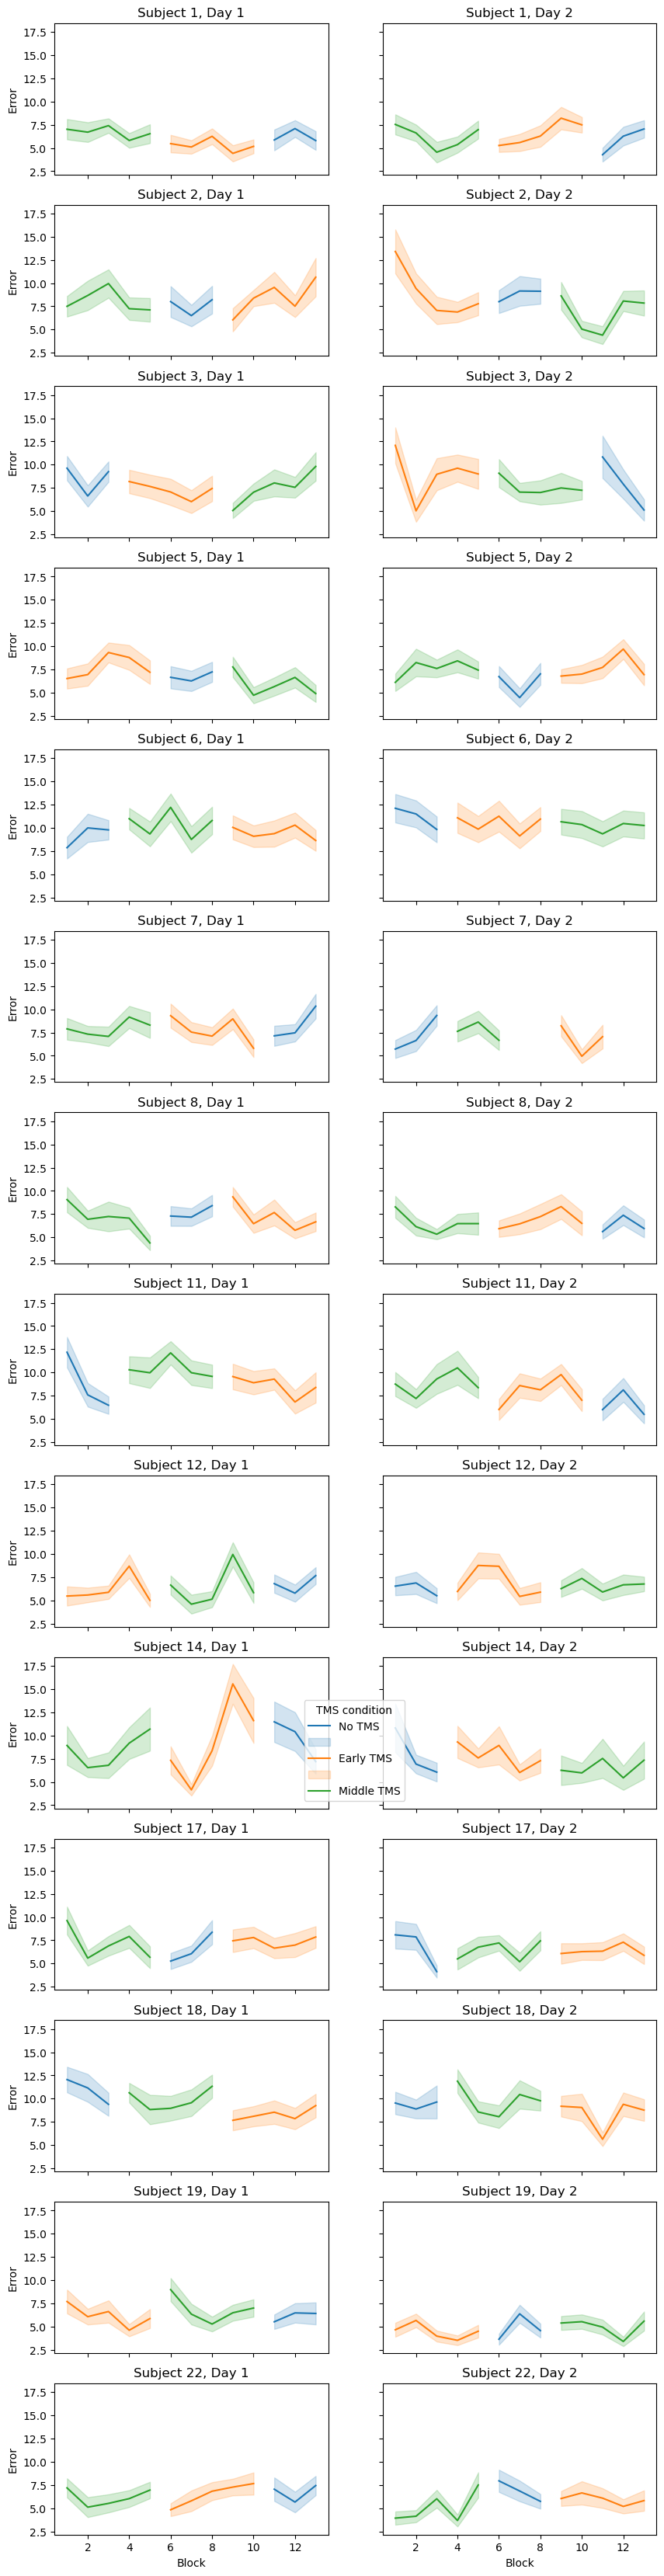

In [4]:
unique_subs = df['subjID'].unique()
f, axs = plt.subplots(len(unique_subs), 2, figsize=(10, 3*len(unique_subs)), sharex=True, sharey=True)

metric_to_plot = 'abserrorOri'
# metric_to_plot = 'RT'
for i, sub in enumerate(unique_subs):
    subdf = df[df['subjID'] == sub]
    # Eliminate rows where abserrorOri is greater than 3 std devs from the mean
    elimTrials = np.abs(subdf['abserrorOri'] - subdf['abserrorOri'].mean()) > 3*subdf['abserrorOri'].std()
    print(f'Subject {sub} has {elimTrials.sum()} trials with abserrorOri > 3 std devs from the mean')
    subdf = subdf[~elimTrials]

    # Plot distributions for RT and error
    nunique_days = subdf['day'].nunique()


    if nunique_days == 1:
        sns.lineplot(x='block', y=metric_to_plot, hue='TMScond_label', data=subdf, ax=axs[i, 0], errorbar='se', legend=False, hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
        axs[i, 0].set_title(f'Subject {sub}, Day 1')
        axs[i, 0].set_xlabel('Block')
        if metric_to_plot == 'abserrorOri':
            axs[i, 0].set_ylabel('Error')
        else:
            axs[i, 0].set_ylabel('RT')
        # axs[i, 0].legend(title='Stimulus position')
    else:
        
        sns.lineplot(x='block', y=metric_to_plot, hue='TMScond_label', data=subdf[subdf['day']==1], ax=axs[i, 0], errorbar='se', legend=False, hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
        axs[i, 0].set_title(f'Subject {sub}, Day 1')
        axs[i, 0].set_xlabel('Block')
        if metric_to_plot == 'abserrorOri':
            axs[i, 0].set_ylabel('Error')
        else:
            axs[i, 0].set_ylabel('RT')
        # axs[i, 0].legend(title='Stimulus position')

        sns.lineplot(x='block', y=metric_to_plot, hue='TMScond_label', data=subdf[subdf['day']==2], ax=axs[i, 1], errorbar='se', legend=False, hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
        axs[i, 1].set_title(f'Subject {sub}, Day 2')
        axs[i, 1].set_xlabel('Block')
        if metric_to_plot == 'abserrorOri':
            axs[i, 1].set_ylabel('Error')
        else:
            axs[i, 1].set_ylabel('RT')
# plt.legend(title='TMS condition', loc='upper right')
plt.legend(title='TMS condition', loc='upper right', bbox_to_anchor=(0.1, 5.55), labels=['No TMS', None, 'Early TMS', '', 'Middle TMS'])
# plt.tight_layout()
plt.show()

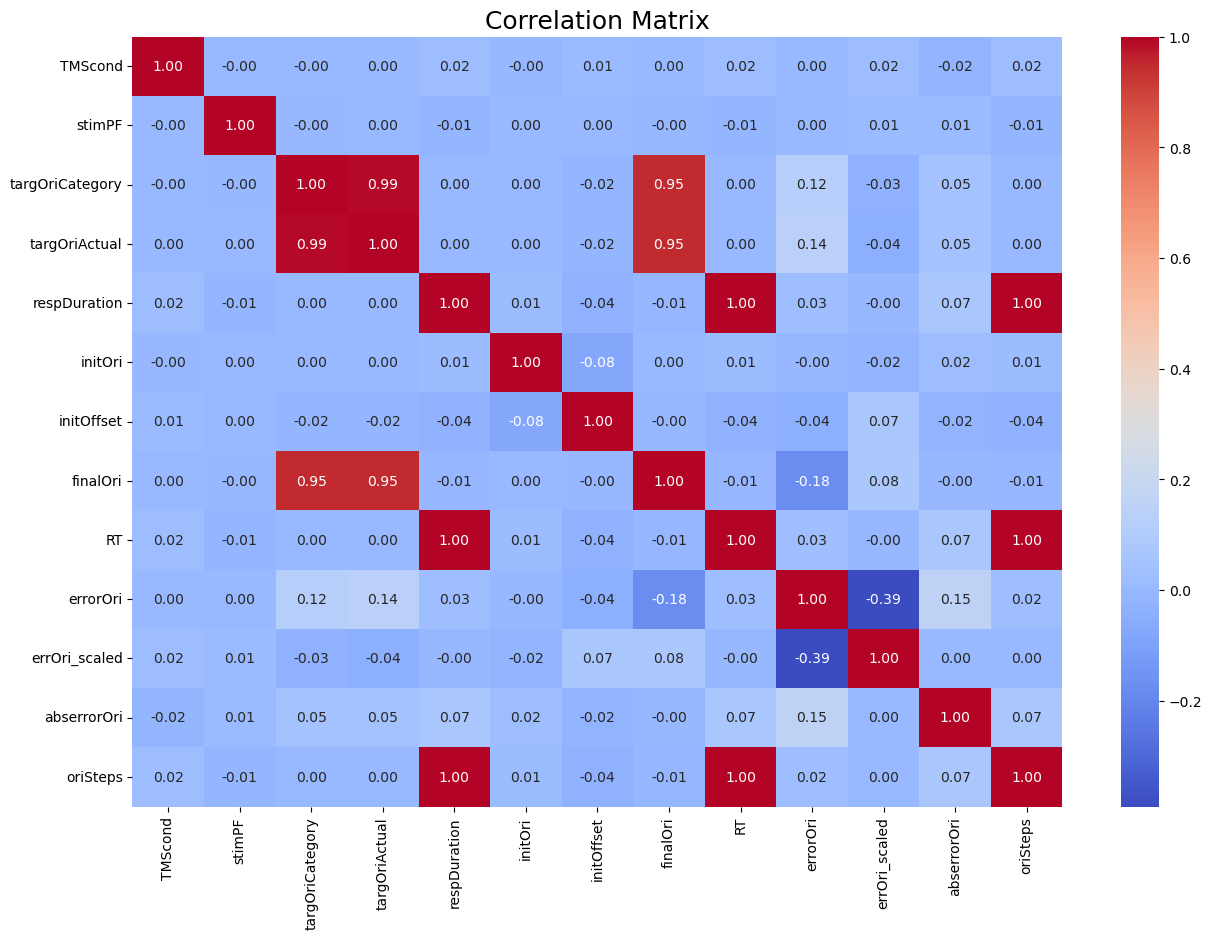

In [4]:
exploratory_cols = ['TMScond', 'stimPF', 'targOriCategory', 'targOriActual', 'respDuration', 'initOri', 'initOffset', 'finalOri', 'RT', 'errorOri', 'errOri_scaled', 'abserrorOri', 'oriSteps']
plt.figure(figsize=(15, 10))
sns.heatmap(df[exploratory_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix', fontsize=title_fontsize)
plt.show()

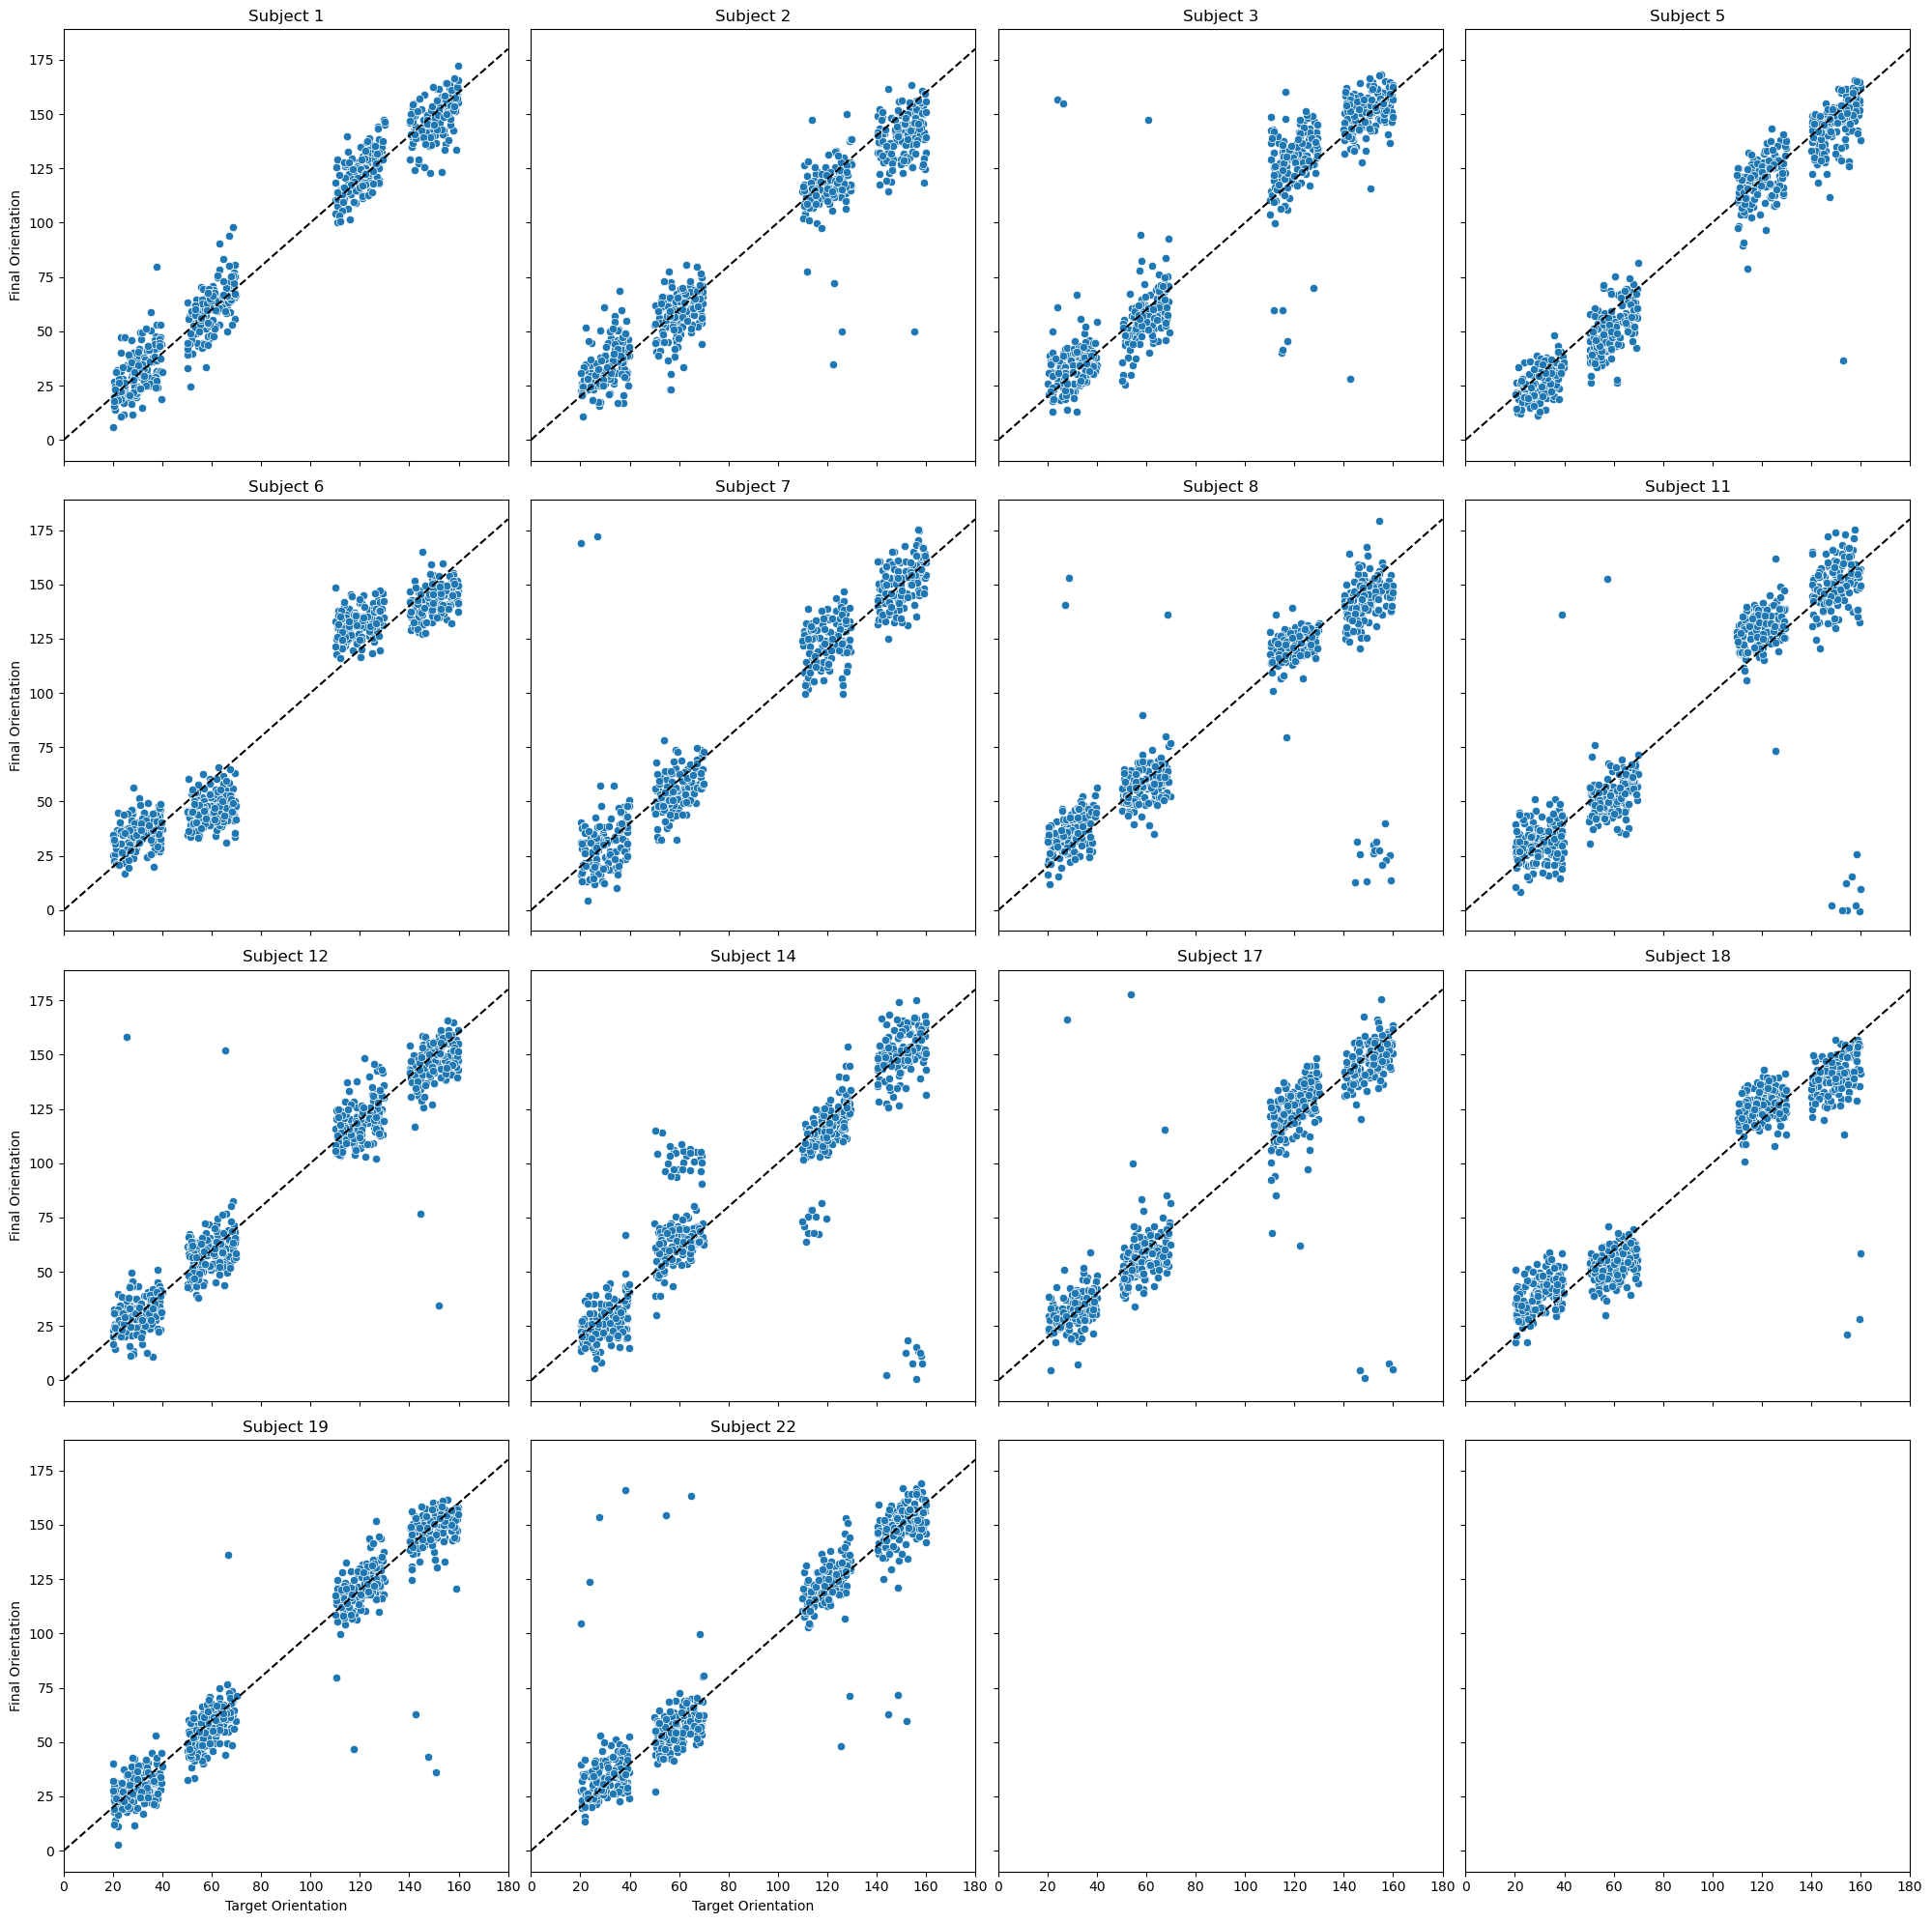

In [5]:
# Explore raw reports and biases
nrows = 4
ncols = df['subjID'].nunique() // nrows + 1
f, axs = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows), sharex=True, sharey=True)
for i, s in enumerate(df['subjID'].unique()):
    subdf = df[df['subjID']==s]
    sns.scatterplot(x='targOriActual', y='finalOri', data=subdf, ax=axs[i//ncols, i%ncols])
    axs[i//ncols, i%ncols].plot([0, 180], [0, 180], 'k--')
    axs[i//ncols, i%ncols].set_xlim([0, 180])
    axs[i//ncols, i%ncols].set_title(f'Subject {s}')
    axs[i//ncols, i%ncols].set_xlabel('Target Orientation')
    axs[i//ncols, i%ncols].set_ylabel('Final Orientation')
plt.tight_layout()
plt.show()

# Observations:
# All participants exhibit a strong tendency to report the target orientation
# subjects 3, 6, 11, 14, 17, 18, 22 show a bias towards 45 and 135 degrees
# We can also see some subjects have few trials that are extremey off from the target orientation, probably they did not look at the target or were lost in their imagination

<Figure size 1500x1000 with 0 Axes>

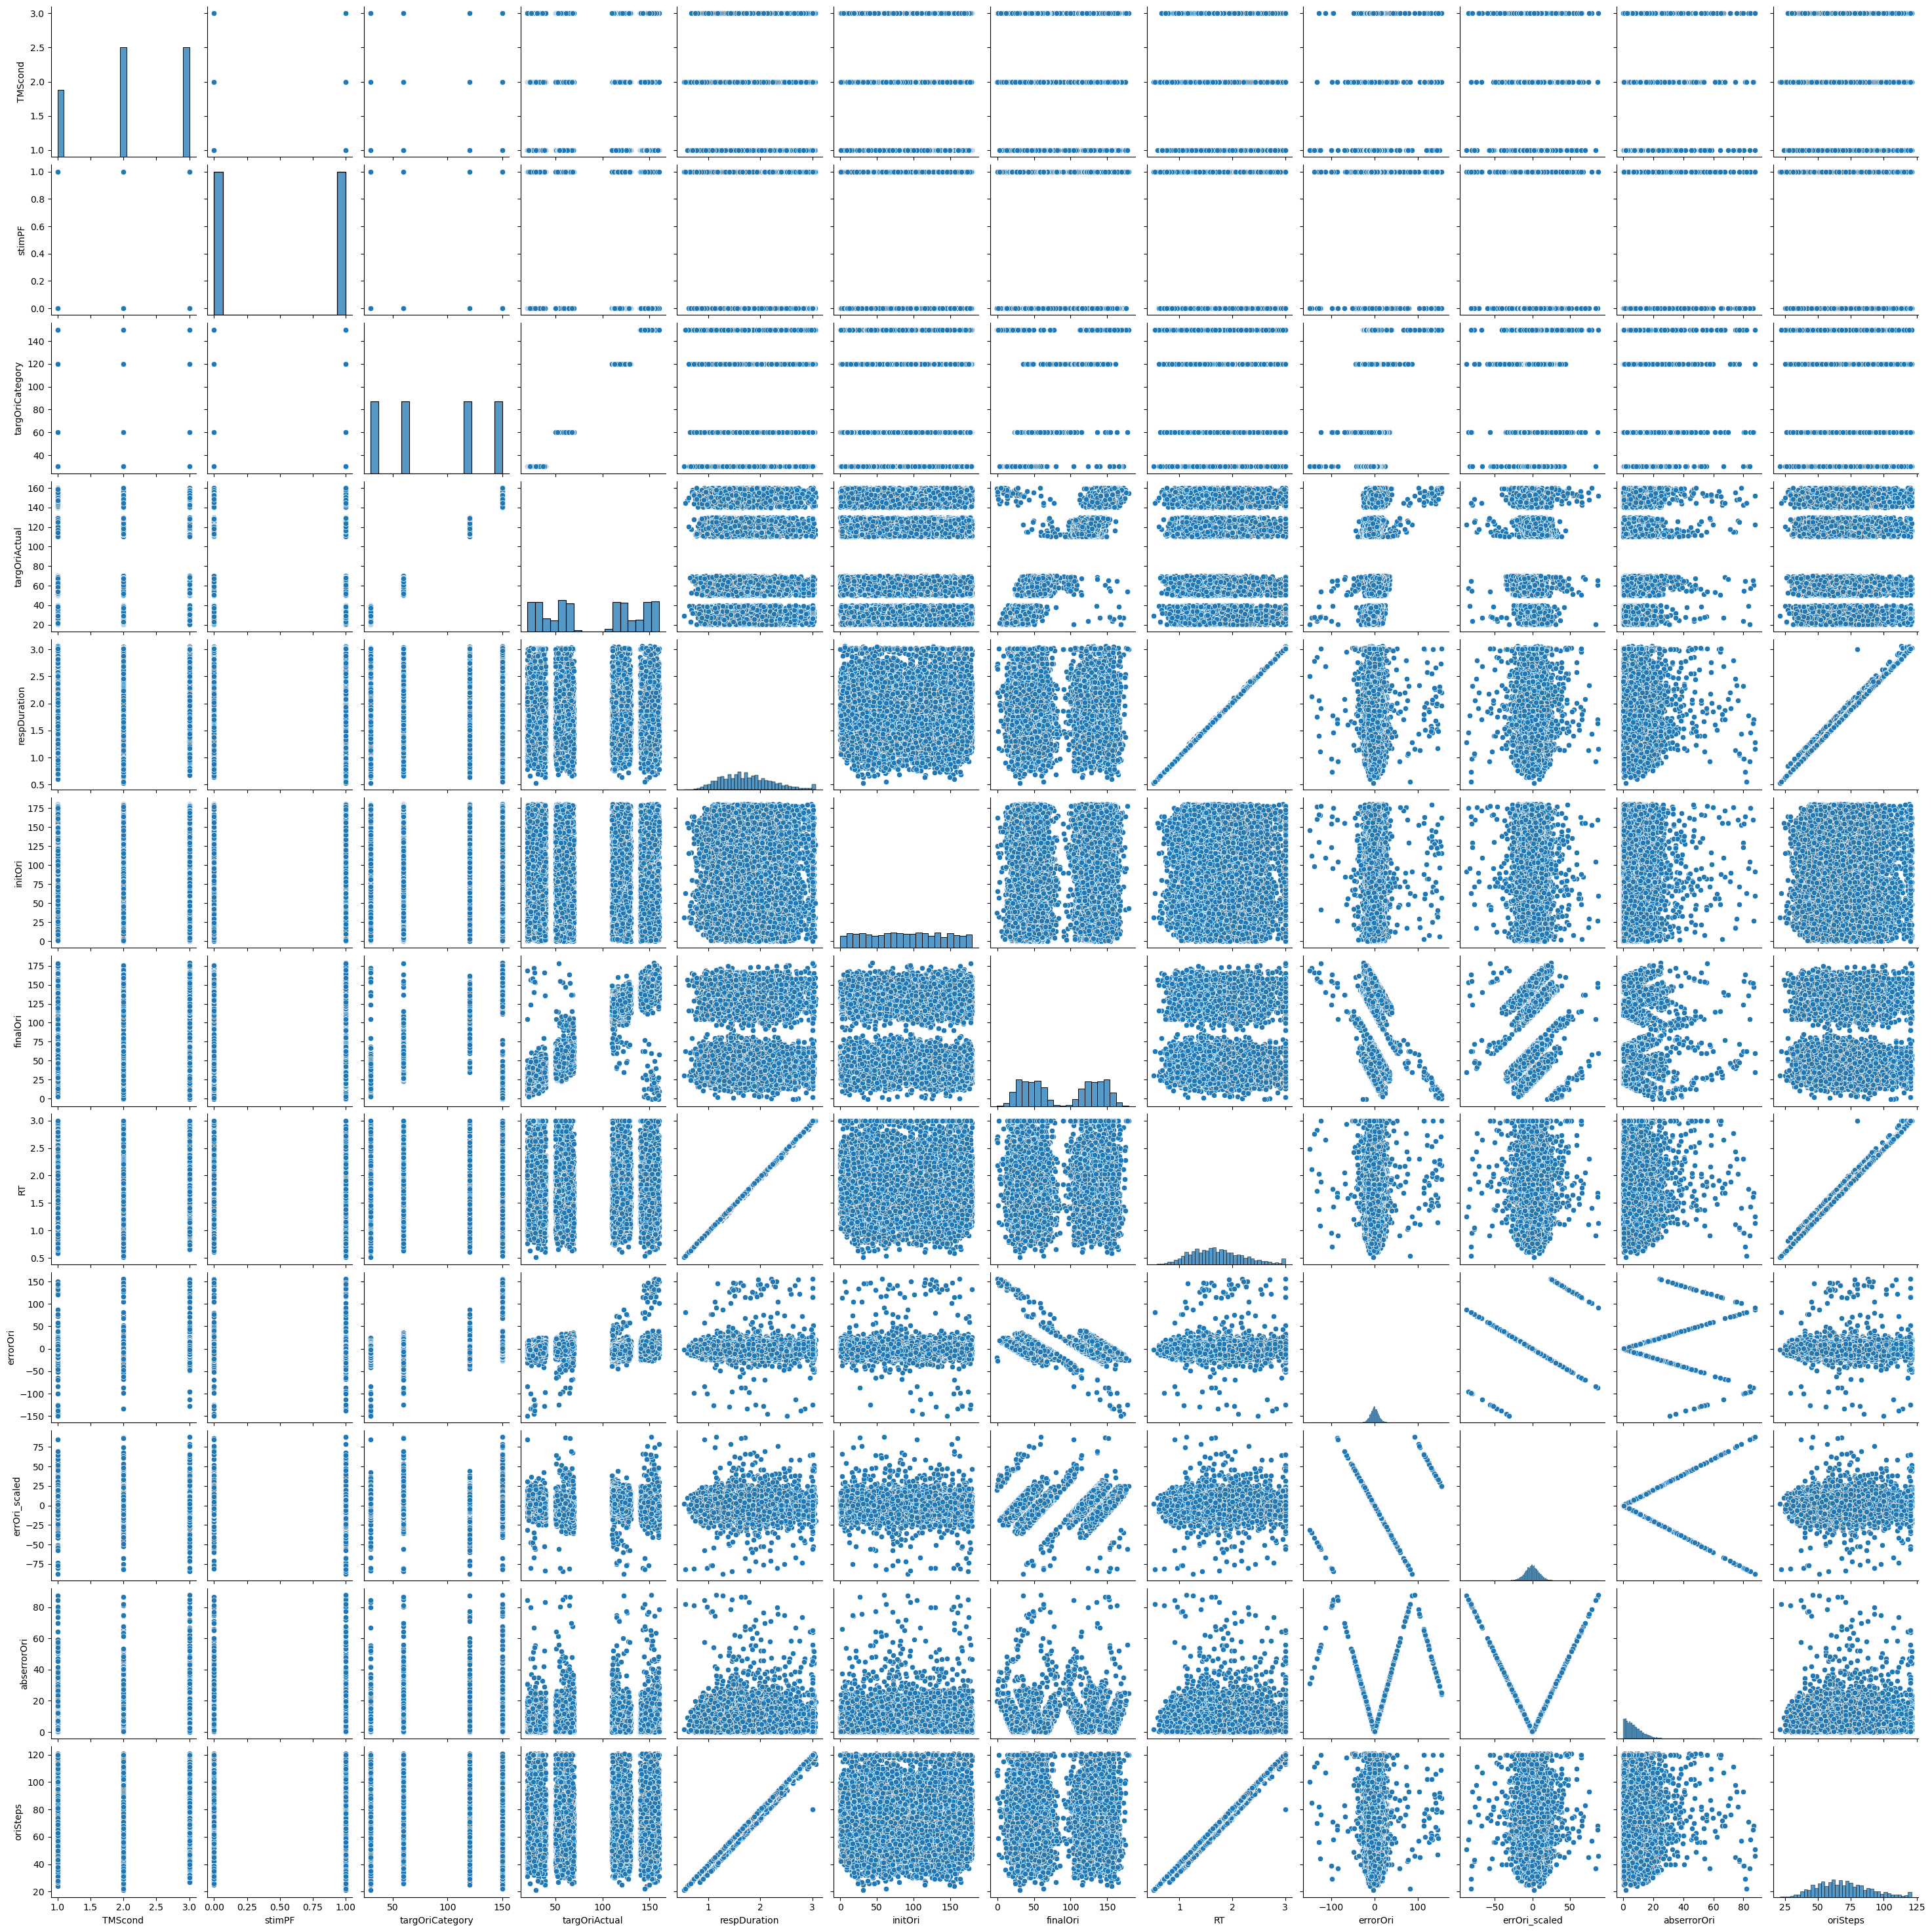

In [13]:
plt.figure(figsize=(15, 10))
sns.pairplot(df[exploratory_cols])
plt.show()

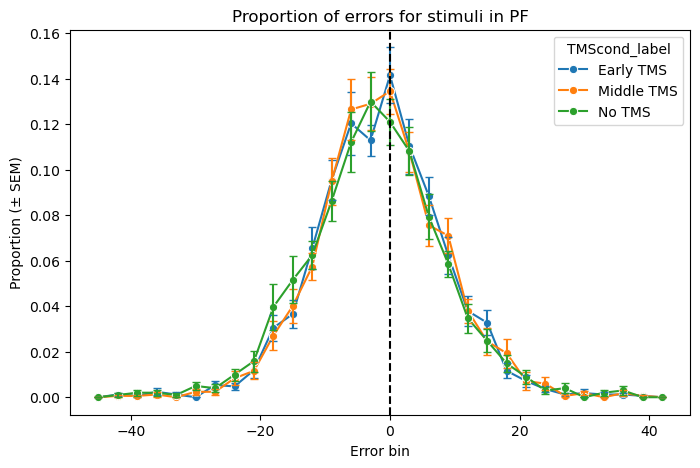

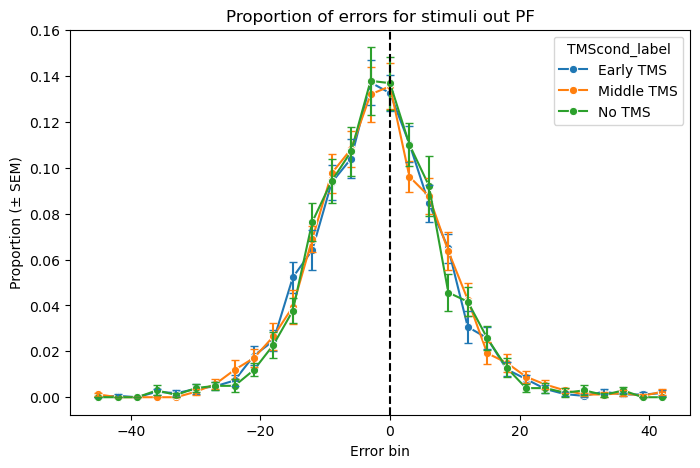

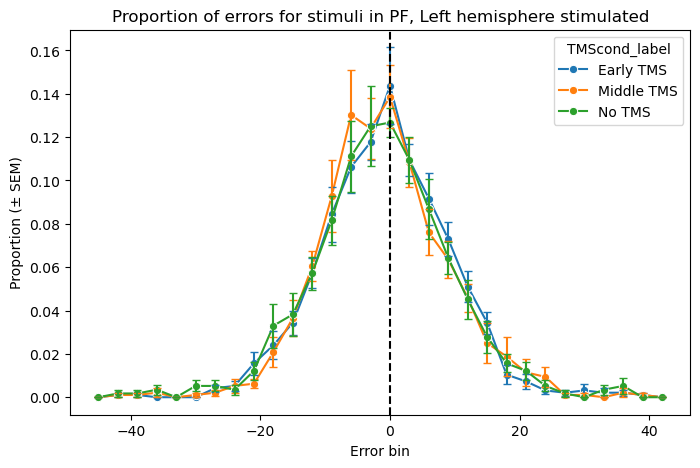

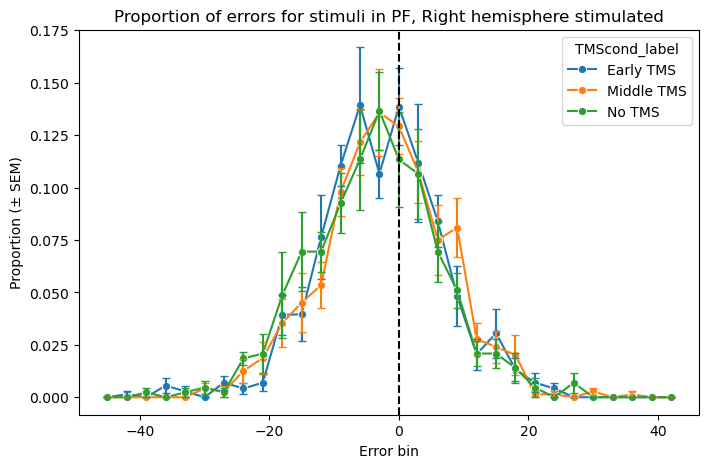

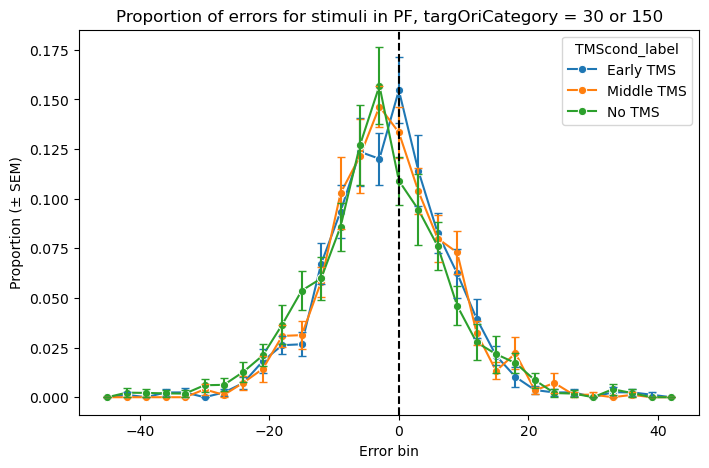

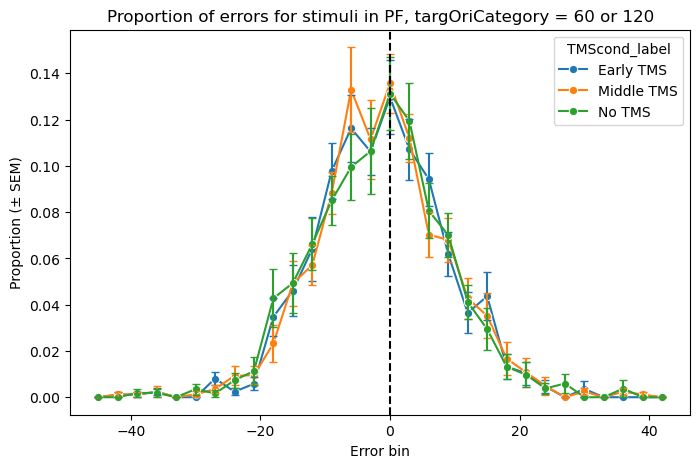

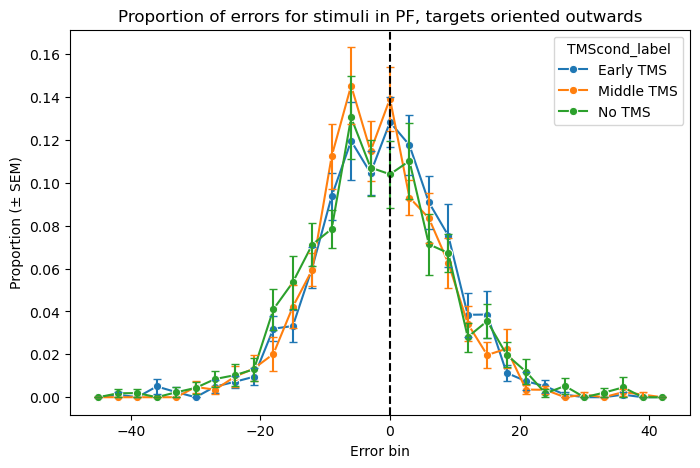

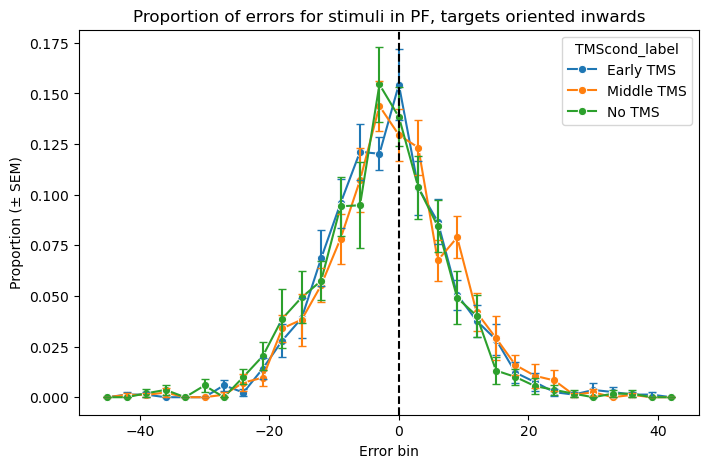

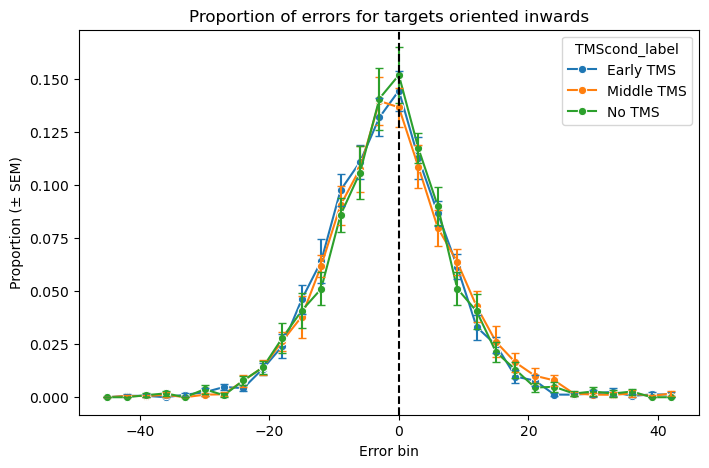

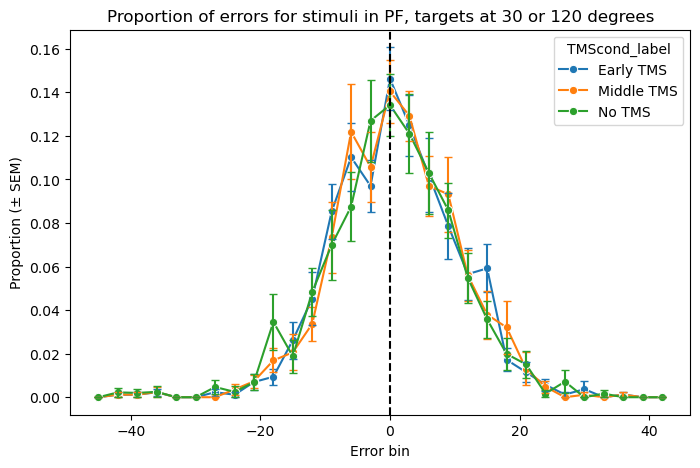

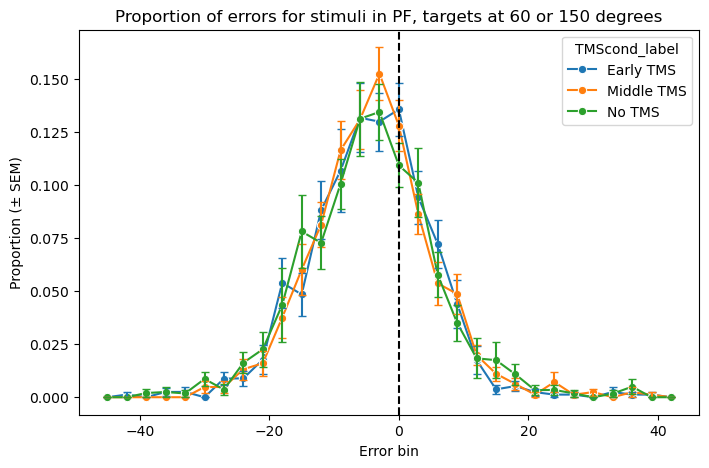

In [6]:
def get_binned_errors(df, metric_to_plot, eval_bins):
    '''
    Function to bin the errors into equal bins to compute histograms
    '''
    error_binned = pd.cut(df[metric_to_plot], eval_bins, labels=eval_bins[:-1])
    return error_binned

def plot_bins(bin_counts, total_counts, title):
    bin_counts = pd.merge(bin_counts, total_counts, on=['subjID', 'TMScond_label'])
    bin_counts['proportion'] = bin_counts['bin_count'] / bin_counts['total_trials']

    final_grouped = bin_counts.groupby(['errorOri_bin', 'TMScond_label'], observed=False).agg(
        mean_proportion=('proportion', 'mean'),
        sem_proportion=('proportion', 'sem')).reset_index()

    plt.figure(figsize=(8, 5))
    sns.lineplot(
        x='errorOri_bin', 
        y='mean_proportion', 
        hue='TMScond_label', 
        data=final_grouped, 
        marker='o', 
        err_style='bars', 
        errorbar=None)
    for cond_label in final_grouped['TMScond_label'].unique():
        cond_data = final_grouped[final_grouped['TMScond_label'] == cond_label]
        plt.errorbar(
            cond_data['errorOri_bin'].astype(float), 
            cond_data['mean_proportion'], 
            yerr=cond_data['sem_proportion'], 
            fmt='none', 
            capsize=3, 
            color=sns.color_palette()[list(final_grouped['TMScond_label'].unique()).index(cond_label)]
        )
    plt.axvline(0, color='black', linestyle='--')
    plt.xlabel('Error bin')
    plt.ylabel('Proportion (± SEM)')
    plt.title(title)
    plt.show()

n_bins = 30
eval_bins = np.linspace(-45, 45, n_bins+1)
df_temp = df.copy()
df_temp['errorOri_bin'] = get_binned_errors(df_temp, 'errOri_scaled', eval_bins)

# Plot for stimulus in PF
total_counts = df_temp[df_temp['stimPF'] == 1].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[df_temp['stimPF'] == 1].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF')

# Plot for stimulus out PF
total_counts = df_temp[df_temp['stimPF'] == 0].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[df_temp['stimPF'] == 0].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli out PF')

# Plot for when stimPF == 1, if hemisphere is Left
total_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Left')].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Left')].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, Left hemisphere stimulated')

# Plot for when stimPF == 1, if hemisphere is Right
total_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Right')].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Right')].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, Right hemisphere stimulated')

# Plot for when stimPF == 1, targOriCategory = 30 or 150
total_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([30, 150]))].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([30, 150]))].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, targOriCategory = 30 or 150')

# Plot for when stimPF == 1, targOriCategory = 60 or 120
total_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([60, 120]))].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([60, 120]))].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, targOriCategory = 60 or 120')

# Plot for when stimPF == 1, hemisphereStimulated = Left, targOriCategory = 30 or 60 or hemisphereStimulated = Right, targOriCategory = 120 or 150
total_counts = df_temp[((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Left') & (df_temp['targOriCategory'].isin([30, 60]))) | ((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Right') & (df_temp['targOriCategory'].isin([120, 150])))].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Left') & (df_temp['targOriCategory'].isin([30, 60]))) | ((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Right') & (df_temp['targOriCategory'].isin([120, 150])))].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, targets oriented outwards')

# Plot for when stimPF == 1, hemisphereStimulated = Left, and (stimPF == 1 and targOriCategory = 120 or 150) or hemisphereStimulated = Right, and (stimPF == 1 and targOriCategory = 30 or 60)
total_counts = df_temp[((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Left') & (df_temp['targOriCategory'].isin([120, 150]))) | ((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Right') & (df_temp['targOriCategory'].isin([30, 60])))].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Left') & (df_temp['targOriCategory'].isin([120, 150]))) | ((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Right') & (df_temp['targOriCategory'].isin([30, 60])))].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, targets oriented inwards')

# Plot for when hemisphereStimulated = Left, and (stimPF == 1 and targOriCategory = 120 or 150 or stimPF == 0 and targOriCategory = 30 or 60) or hemisphereStimulated = Right, and (stimPF == 1 and targOriCategory = 30 or 60 or stimPF == 0 and targOriCategory = 120 or 150)
total_counts = df_temp[(df_temp['hemisphereStimulated'] == 'Left') & ((df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([120, 150])) | (df_temp['stimPF'] == 0) & (df_temp['targOriCategory'].isin([30, 60]))) | (df_temp['hemisphereStimulated'] == 'Right') & ((df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([30, 60])) | (df_temp['stimPF'] == 0) & (df_temp['targOriCategory'].isin([120, 150])) )].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['hemisphereStimulated'] == 'Left') & ((df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([120, 150])) | (df_temp['stimPF'] == 0) & (df_temp['targOriCategory'].isin([30, 60]))) | (df_temp['hemisphereStimulated'] == 'Right') & ((df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([30, 60])) | (df_temp['stimPF'] == 0) & (df_temp['targOriCategory'].isin([120, 150])) )].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for targets oriented inwards')

# Plot for when stimPF == 1, and targOri = 30 or 120
total_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([30, 120]))].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([30, 120]))].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, targets at 30 or 120 degrees')

# Plot for when stimPF == 1, and targOri = 60 or 150
total_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([60, 150]))].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([60, 150]))].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, targets at 60 or 150 degrees')

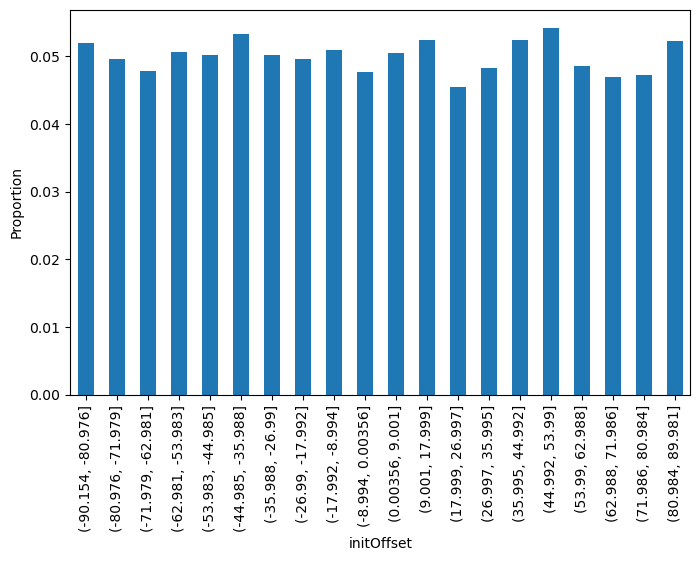

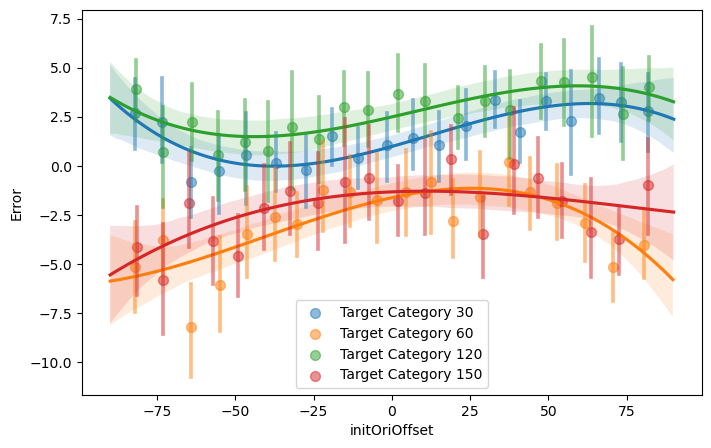

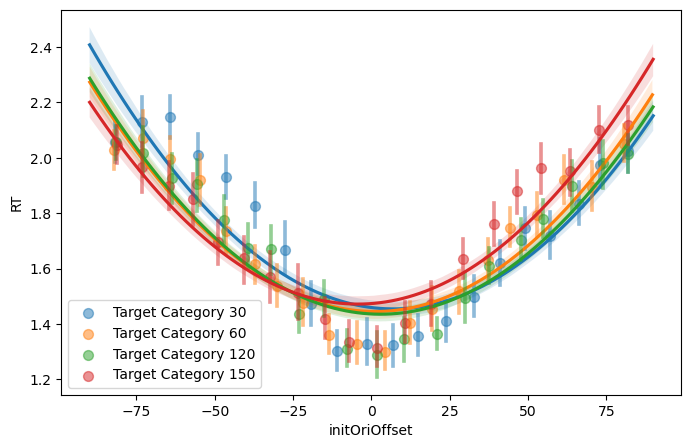

In [7]:
df_temp = df.copy()
# df_temp['errOri_nobias'] = np.nan
# Fit a 4th order polynomial to the error data and remove the bias for each subject
for i, sidx in enumerate(df_temp['subjID'].unique()):
    subdf = df_temp[df_temp['subjID'] == sidx]
    errorVals = subdf['errOri_scaled'].values
    
    # Fit a 4th order polynomial to the error data
    # x = subdf['targOriActual'].values
    # y = errorVals
    # model = np.poly1d(np.polyfit(x, y, 4))
    # yfit = model(x)
    # df_temp.loc[df_temp['subjID'] == sidx, 'errOri_scaled'] = errorVals - yfit

# Check if error depends on initial Ori
bin_labels = pd.cut(df_temp['initOffset'], bins=20)
bin_counts = bin_labels.value_counts(normalize=True).sort_index()
bin_counts.plot(kind='bar', figsize=(8, 5))
plt.xlabel('initOffset')
plt.ylabel('Proportion')
plt.show()

# Impact of initial orientation offset on error
plt.figure(figsize=(8, 5))
sns.regplot(x='initOffset', y='errOri_scaled', data=df_temp[df_temp['targOriCategory'] == 30], label='Target Category 30', scatter_kws={'alpha': 0.5}, x_bins=20, order=3)
sns.regplot(x='initOffset', y='errOri_scaled', data=df_temp[df_temp['targOriCategory'] == 60], label='Target Category 60', scatter_kws={'alpha': 0.5}, x_bins=20, order=3)
sns.regplot(x='initOffset', y='errOri_scaled', data=df_temp[df_temp['targOriCategory'] == 120], label='Target Category 120', scatter_kws={'alpha': 0.5}, x_bins=20, order=3)
sns.regplot(x='initOffset', y='errOri_scaled', data=df_temp[df_temp['targOriCategory'] == 150], label='Target Category 150', scatter_kws={'alpha': 0.5}, x_bins=20, order=3)
plt.legend()
plt.xlabel('initOriOffset')
plt.ylabel('Error')
plt.show()

# Impact of initial orientation offset on RT
plt.figure(figsize=(8, 5))
sns.regplot(x='initOffset', y='RT', data=df_temp[df_temp['targOriCategory'] == 30], label='Target Category 30', scatter_kws={'alpha': 0.5}, x_bins=20, order=2)
sns.regplot(x='initOffset', y='RT', data=df_temp[df_temp['targOriCategory'] == 60], label='Target Category 60', scatter_kws={'alpha': 0.5}, x_bins=20, order=2)
sns.regplot(x='initOffset', y='RT', data=df_temp[df_temp['targOriCategory'] == 120], label='Target Category 120', scatter_kws={'alpha': 0.5}, x_bins=20, order=2)
sns.regplot(x='initOffset', y='RT', data=df_temp[df_temp['targOriCategory'] == 150], label='Target Category 150', scatter_kws={'alpha': 0.5}, x_bins=20, order=2)
plt.legend()
plt.xlabel('initOriOffset')
plt.ylabel('RT')
plt.show()

# Observations:
# Error:
# Initial orientation offset has an impact on error in reported orientation
# For 30 and 120, errors are largely positive aka counterclockwise bias in reporting (i.e. bias towars 45 degree and 135 degree respectively)
# For 30 and 120, if initial offset is 0 to +45, errors are more biased towards 45/135, if initial offset is -45 to 0, the bias is removed
# For 30 and 120, if initial offset is +45 to +90, the bias is reduced, but if it is -45 to -90, the bias is increased

# For 60 and 150, errors are largely negative aka clockwise bias in reporting (i.e. bias towards 45 degree and 135 degree respectively)
# For 60, sweetspot is when response cue is 45 dgrees counterclockwise to target Ori, if it is more clockwise, reports are more biased towards 45
# Additionally, any response offset below 45, even if it is clockwise, reports are biased towards 45
# For 150, sweetspot is for a broader range between -45 and +45 and does not show a strong bias
# However, if response cue is 45 degrees ore more clockwise or counterclockwise, reports are biased towards 135

# RT:
# RT depends on initOffset severely. Faster responses when target Ori is close to initial Ori
# RT vs initOffset is quadratic in nature, looks symmetric for targOri 60 and 120, Looks asymmetric for targOri 30 and 150 
# for 30, slower than usual responses when response Cue is clockwise to target Ori
# for 150, slower than usual responses when response Cue is counterclockwise to target Ori
# Basically for 30 and 150, when response cue is downwards, RT decreases

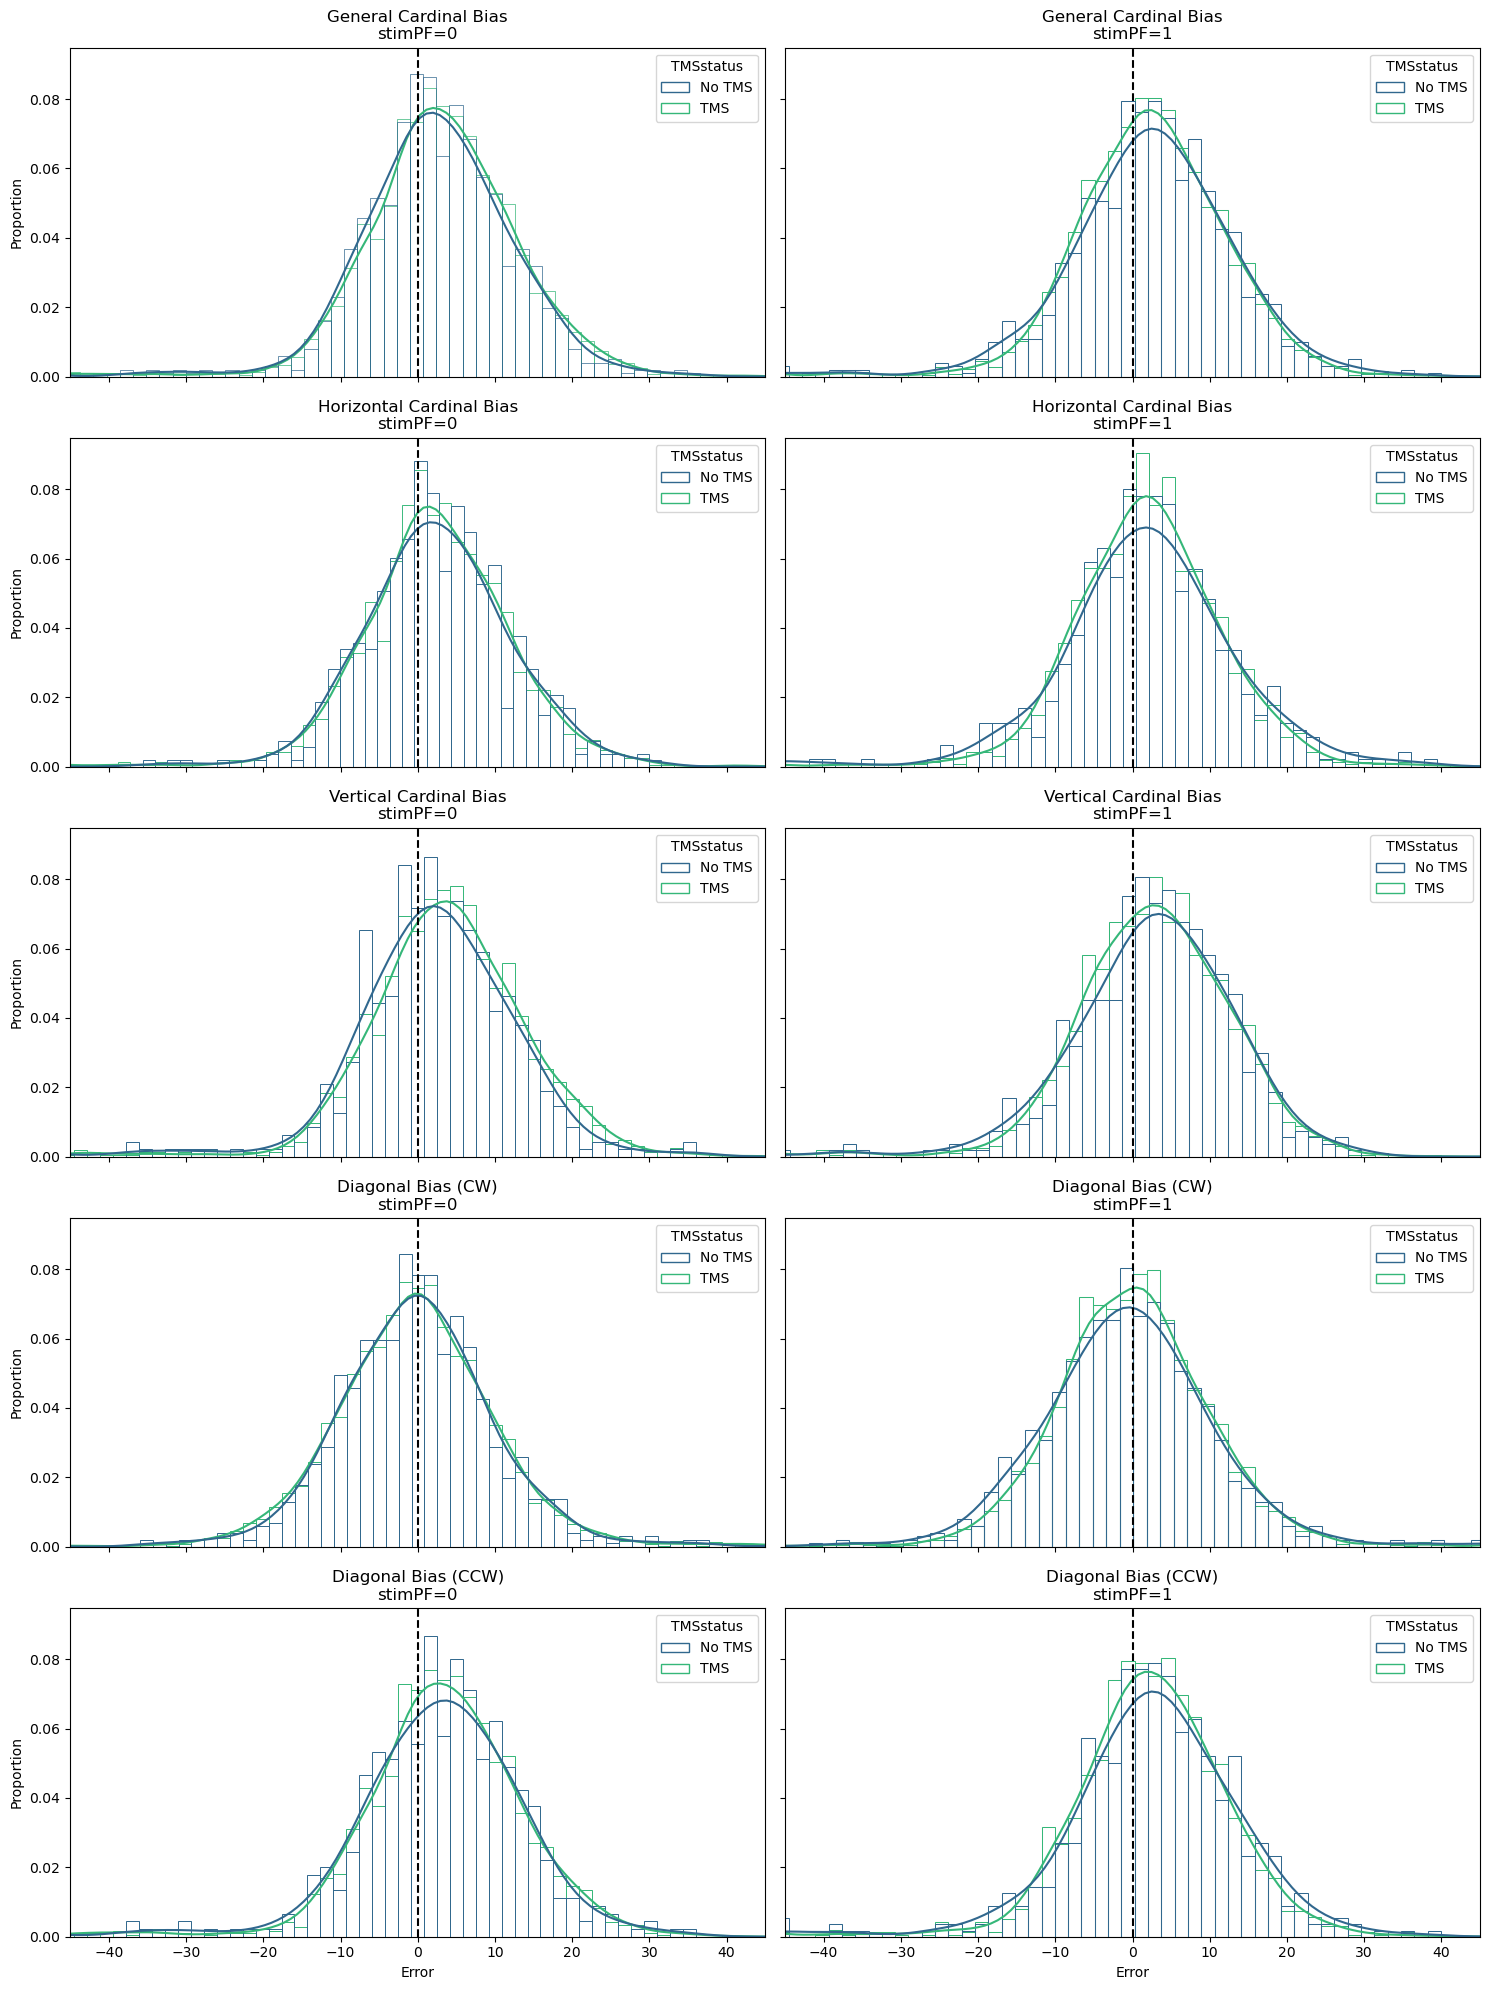

In [30]:
# Hunting for biases relative to horizontal and vertical meridians
fig, axes = plt.subplots(5, 2, figsize=(15, 20), sharey=True, sharex=True)

metric = 'errOri_scaled'
if metric == 'errOri_scaled':
    xlim = [-45, 45]
elif metric == 'abserrorOri':
    xlim = [0, 45]

# Iterate over the two values of stimPF
for i, stimPF_val in enumerate([0, 1]):
    df_temp = df[df['stimPF'] == stimPF_val].copy()

    idx30 = df_temp['targOriCategory'] == 30
    idx60 = df_temp['targOriCategory'] == 60
    idx120 = df_temp['targOriCategory'] == 120
    idx150 = df_temp['targOriCategory'] == 150

    # General cardinal bias
    df_temp_gen = df_temp.copy()
    df_temp_gen.loc[idx60, 'errOri_scaled'] = -df_temp_gen.loc[idx60, 'errOri_scaled']
    df_temp_gen.loc[idx150, 'errOri_scaled'] = -df_temp_gen.loc[idx150, 'errOri_scaled']
    sns.histplot(
        x=metric, data=df_temp_gen, bins=100, kde=True, palette='viridis', hue='TMSstatus',
        hue_order=['No TMS', 'TMS'], fill=False, stat='probability', common_norm=False, ax=axes[0, i]
    )
    axes[0, i].axvline(0, color='black', linestyle='--')
    axes[0, i].set_xlim(xlim)
    axes[0, i].set_title(f'General Cardinal Bias\nstimPF={stimPF_val}')
    axes[0, i].set_xlabel('Error')
    axes[0, i].set_ylabel('Proportion')

    # Horizontal cardinal bias
    df_temp_hor = df_temp.copy()
    df_temp_hor.loc[idx150, 'errOri_scaled'] = -df_temp_hor.loc[idx150, 'errOri_scaled']
    df_temp_hor = df_temp_hor[~idx60 & ~idx120]
    sns.histplot(
        x=metric, data=df_temp_hor, bins=100, kde=True, palette='viridis', hue='TMSstatus',
        hue_order=['No TMS', 'TMS'], fill=False, stat='probability', common_norm=False, ax=axes[1, i]
    )
    axes[1, i].axvline(0, color='black', linestyle='--')
    axes[1, i].set_xlim(xlim)
    axes[1, i].set_title(f'Horizontal Cardinal Bias\nstimPF={stimPF_val}')
    axes[1, i].set_xlabel('Error')
    axes[1, i].set_ylabel('Proportion')

    # Vertical cardinal bias
    df_temp_vert = df_temp.copy()
    df_temp_vert.loc[idx60, 'errOri_scaled'] = -df_temp_vert.loc[idx60, 'errOri_scaled']
    df_temp_vert = df_temp_vert[~idx30 & ~idx150]
    sns.histplot(
        x=metric, data=df_temp_vert, bins=100, kde=True, palette='viridis', hue='TMSstatus',
        hue_order=['No TMS', 'TMS'], fill=False, stat='probability', common_norm=False, ax=axes[2, i]
    )
    axes[2, i].axvline(0, color='black', linestyle='--')
    axes[2, i].set_xlim(xlim)
    axes[2, i].set_title(f'Vertical Cardinal Bias\nstimPF={stimPF_val}')
    axes[2, i].set_xlabel('Error')
    axes[2, i].set_ylabel('Proportion')

    # Bias towards diagonal while rotating clockwise
    df_temp_diag_cw = df_temp.copy()
    df_temo_diag_cw = df_temp_diag_cw[~idx60 & ~idx150]
    sns.histplot(
        x=metric, data=df_temp_diag_cw, bins=100, kde=True, palette='viridis', hue='TMSstatus',
        hue_order=['No TMS', 'TMS'], fill=False, stat='probability', common_norm=False, ax=axes[3, i]
    )
    axes[3, i].axvline(0, color='black', linestyle='--')
    axes[3, i].set_xlim(xlim)
    axes[3, i].set_title(f'Diagonal Bias (CW)\nstimPF={stimPF_val}')
    axes[3, i].set_xlabel('Error')
    axes[3, i].set_ylabel('Proportion')

    # Bias towards diagonal while rotating counterclockwise
    df_temp_diag_ccw = df_temp.copy()
    df_temp_diag_ccw.loc[idx60, 'errOri_scaled'] = -df_temp_diag_ccw.loc[idx60, 'errOri_scaled']
    df_temp_diag_ccw.loc[idx150, 'errOri_scaled'] = -df_temp_diag_ccw.loc[idx150, 'errOri_scaled']
    df_temp_diag_ccw = df_temp_diag_ccw[~idx30 & ~idx120]
    sns.histplot(
        x=metric, data=df_temp_diag_ccw, bins=100, kde=True, palette='viridis', hue='TMSstatus',
        hue_order=['No TMS', 'TMS'], fill=False, stat='probability', common_norm=False, ax=axes[4, i]
    )
    axes[4, i].axvline(0, color='black', linestyle='--')
    axes[4, i].set_xlim(xlim)
    axes[4, i].set_title(f'Diagonal Bias (CCW)\nstimPF={stimPF_val}')
    axes[4, i].set_xlabel('Error')
    axes[4, i].set_ylabel('Proportion')

plt.tight_layout()
plt.show()

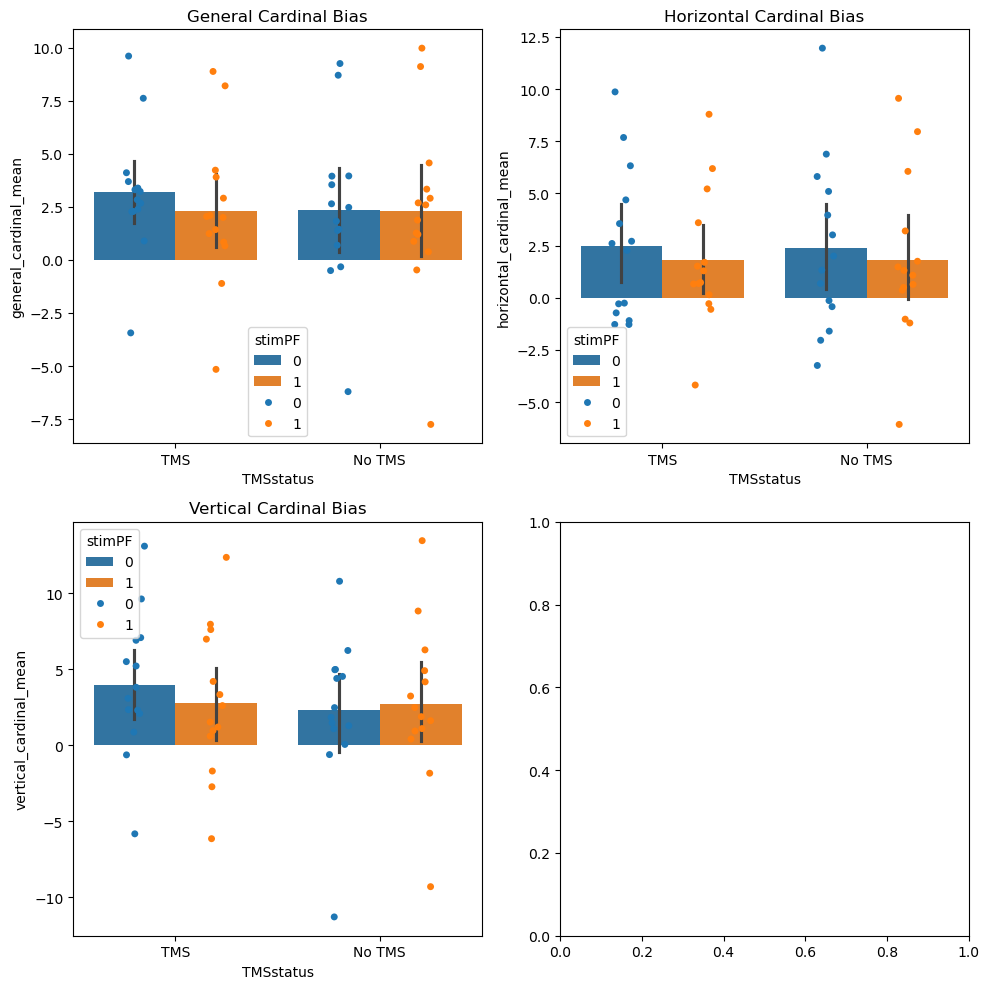

ANOVA for general cardinal bias
               Source      SS  ddof1  ddof2      MS       F   p-unc  \
0              stimPF  2.9975      1     13  2.9975  1.8112  0.2014   
1           TMSstatus  2.4139      1     13  2.4139  1.3681  0.2631   
2  stimPF * TMSstatus  2.7448      1     13  2.7448  5.3647  0.0375   

   p-GG-corr     ng2  eps  
0     0.2014  0.0043  1.0  
1     0.2631  0.0035  1.0  
2     0.0375  0.0040  1.0  
ANOVA for horizontal cardinal bias
               Source      SS  ddof1  ddof2      MS       F   p-unc  \
0              stimPF  5.1401      1     13  5.1401  1.2879  0.2769   
1           TMSstatus  0.0341      1     13  0.0341  0.0211  0.8869   
2  stimPF * TMSstatus  0.0444      1     13  0.0444  0.0570  0.8150   

   p-GG-corr         ng2  eps  
0     0.2769  7.0200e-03  1.0  
1     0.8869  4.6884e-05  1.0  
2     0.8150  6.1054e-05  1.0  
ANOVA for vertical cardinal bias
               Source       SS  ddof1  ddof2       MS        F   p-unc  \
0              s

/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)
/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped 

In [52]:
results = {
    'subjID': [],
    'stimPF': [],
    'TMSstatus': [],
    'general_cardinal_mean': [],
    'horizontal_cardinal_mean': [],
    'vertical_cardinal_mean': [],
    'general_cardinal_var': [],
    'horizontal_cardinal_var': [],
    'vertical_cardinal_var': []
}

for subj in df['subjID'].unique():
    for stimPF_val in [0, 1]:
        for tms_status in df['TMSstatus'].unique():
            df_temp = df[(df['subjID'] == subj) & (df['stimPF'] == stimPF_val) & (df['TMSstatus'] == tms_status)].copy()

            idx30 = df_temp['targOriCategory'] == 30
            idx60 = df_temp['targOriCategory'] == 60
            idx120 = df_temp['targOriCategory'] == 120
            idx150 = df_temp['targOriCategory'] == 150

            # General cardinal bias
            df_temp_gen = df_temp.copy()
            df_temp_gen.loc[idx60, 'errOri_scaled'] = -df_temp_gen.loc[idx60, 'errOri_scaled']
            df_temp_gen.loc[idx150, 'errOri_scaled'] = -df_temp_gen.loc[idx150, 'errOri_scaled']
            general_stats = circ_stats(df_temp_gen['errOri_scaled'].values)
            general_mean = general_stats[0]
            general_var = general_stats[2]

            # Horizontal cardinal bias
            df_temp_hor = df_temp.copy()
            df_temp_hor.loc[idx150, 'errOri_scaled'] = -df_temp_hor.loc[idx150, 'errOri_scaled']
            df_temp_hor = df_temp_hor[~idx60 & ~idx120]
            horizontal_stats = circ_stats(df_temp_hor['errOri_scaled'].values)
            horizontal_mean = horizontal_stats[0]
            horizontal_var = horizontal_stats[2]

            # Vertical cardinal bias
            df_temp_vert = df_temp.copy()
            df_temp_vert.loc[idx60, 'errOri_scaled'] = -df_temp_vert.loc[idx60, 'errOri_scaled']
            df_temp_vert = df_temp_vert[~idx30 & ~idx150]
            vertical_stats = circ_stats(df_temp_vert['errOri_scaled'].values)
            vertical_mean = vertical_stats[0]
            vertical_var = vertical_stats[2]

            # Store the results
            results['subjID'].append(subj)
            results['stimPF'].append(stimPF_val)
            results['TMSstatus'].append(tms_status)
            results['general_cardinal_mean'].append(general_mean)
            results['horizontal_cardinal_mean'].append(horizontal_mean)
            results['vertical_cardinal_mean'].append(vertical_mean)
            results['general_cardinal_var'].append(general_var)
            results['horizontal_cardinal_var'].append(horizontal_var)
            results['vertical_cardinal_var'].append(vertical_var)

results_df = pd.DataFrame(results)

# Plot the results
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

sns.barplot(x='TMSstatus', y='general_cardinal_mean', data=results_df, hue='stimPF', ax=axes[0, 0])
sns.stripplot(x='TMSstatus', y='general_cardinal_mean', data=results_df, hue='stimPF', ax=axes[0, 0], dodge=True)
axes[0, 0].set_title('General Cardinal Bias')

sns.barplot(x='TMSstatus', y='horizontal_cardinal_mean', data=results_df, hue='stimPF', ax=axes[0, 1])
sns.stripplot(x='TMSstatus', y='horizontal_cardinal_mean', data=results_df, hue='stimPF', ax=axes[0, 1], dodge=True)
axes[0, 1].set_title('Horizontal Cardinal Bias')

sns.barplot(x='TMSstatus', y='vertical_cardinal_mean', data=results_df, hue='stimPF', ax=axes[1, 0])
sns.stripplot(x='TMSstatus', y='vertical_cardinal_mean', data=results_df, hue='stimPF', ax=axes[1, 0], dodge=True)
axes[1, 0].set_title('Vertical Cardinal Bias')

plt.tight_layout()
plt.show()

# Perform rmANOVA on the results
from pingouin import rm_anova
results_df['subjID'] = results_df['subjID'].astype(str)
results_df['stimPF'] = results_df['stimPF'].astype(str)
results_df['TMSstatus'] = results_df['TMSstatus'].astype(str)

print('ANOVA for general cardinal bias')
aov = rm_anova(data=results_df, dv='general_cardinal_mean', within=['stimPF', 'TMSstatus'], subject='subjID')
print(aov)

print('ANOVA for horizontal cardinal bias')
aov = rm_anova(data=results_df, dv='horizontal_cardinal_mean', within=['stimPF', 'TMSstatus'], subject='subjID')
print(aov)

print('ANOVA for vertical cardinal bias')
aov = rm_anova(data=results_df, dv='vertical_cardinal_mean', within=['stimPF', 'TMSstatus'], subject='subjID')
print(aov)



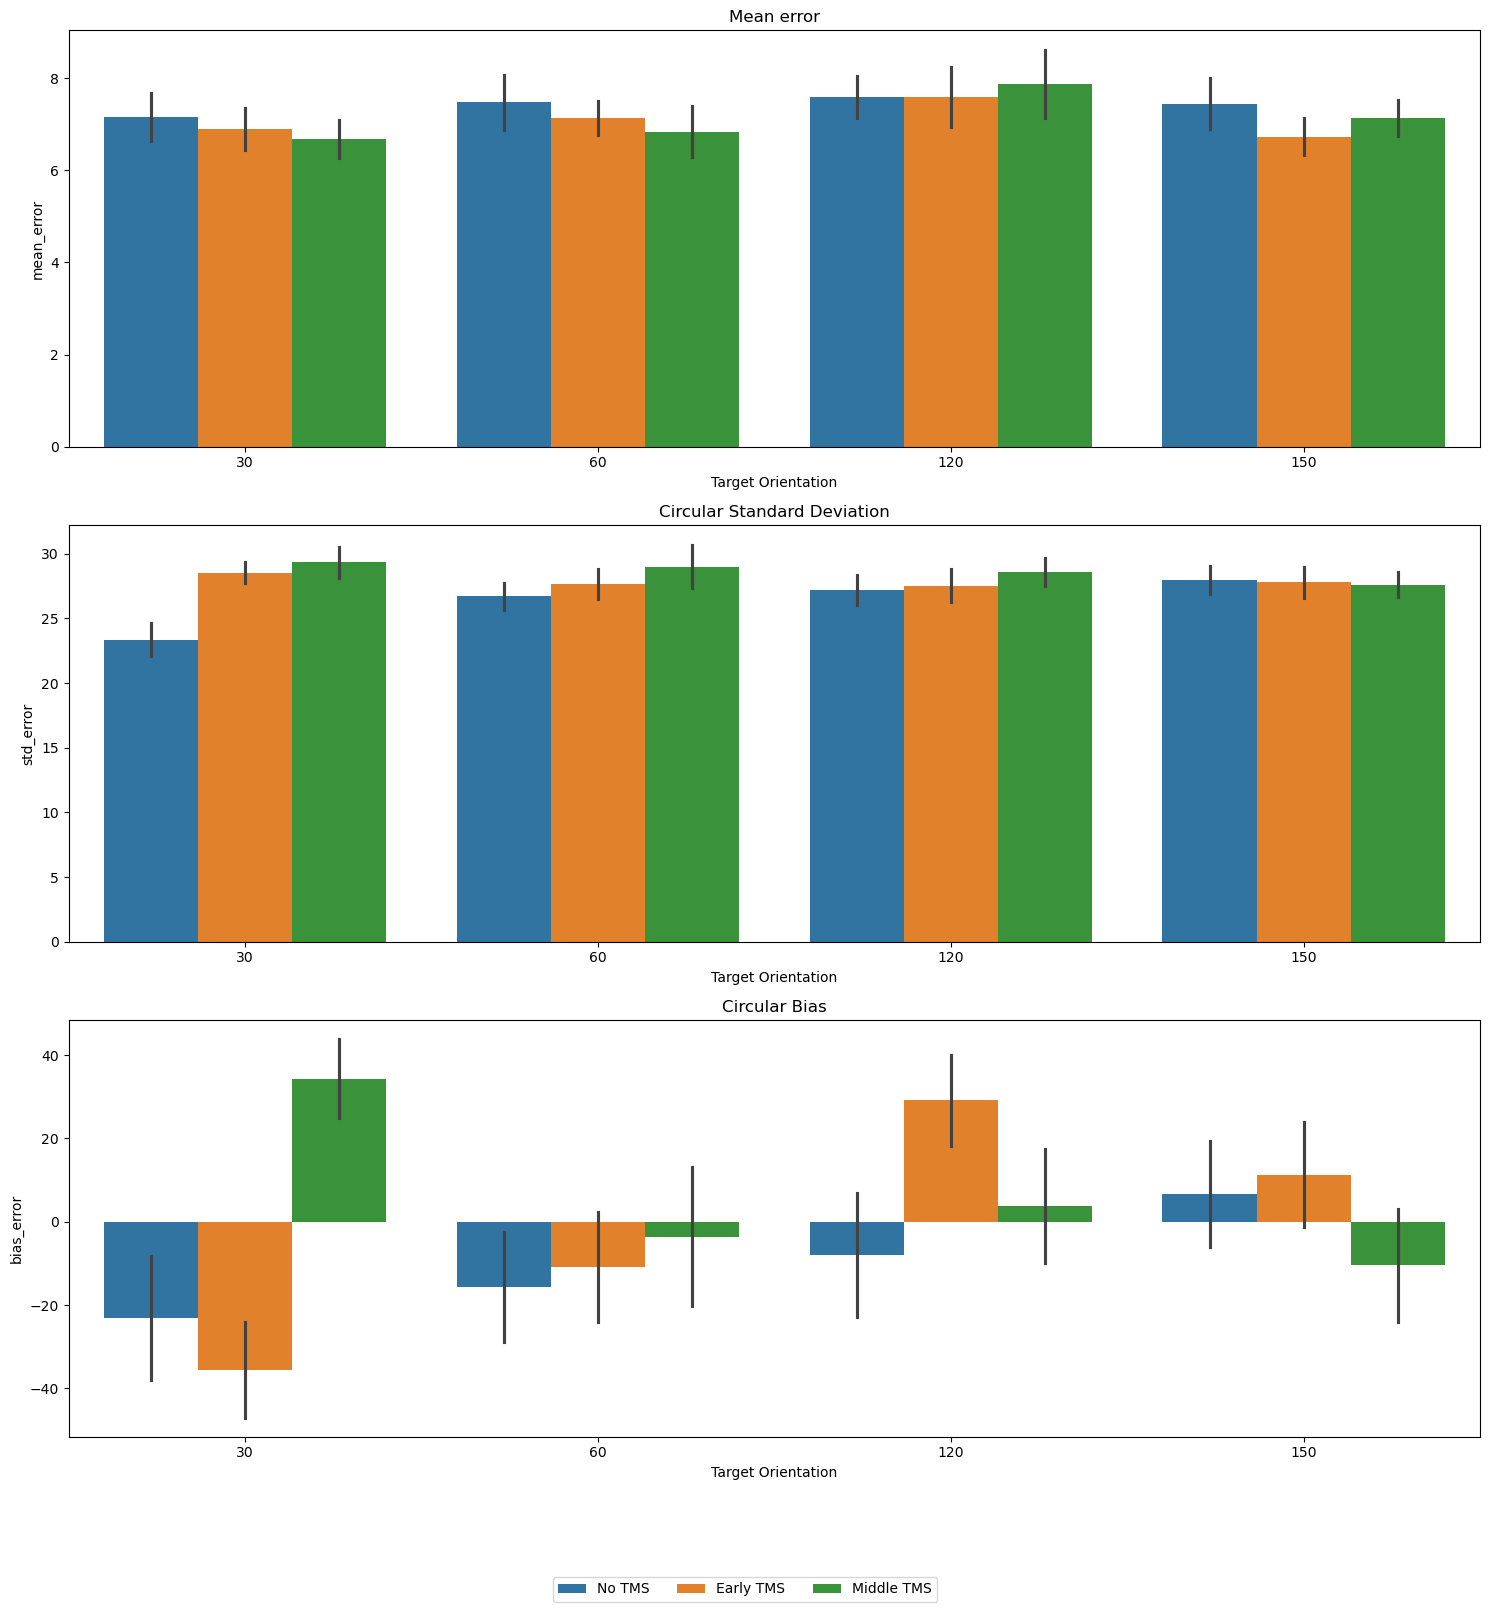

                           Anova
                              F Value Num DF  Den DF Pr > F
-----------------------------------------------------------
TMScond_label                  1.0603 2.0000 26.0000 0.3608
targOriCategory                0.7756 3.0000 39.0000 0.5147
TMScond_label:targOriCategory  0.5965 6.0000 78.0000 0.7322

                           Anova
                              F Value Num DF  Den DF Pr > F
-----------------------------------------------------------
TMScond_label                  4.7679 2.0000 26.0000 0.0172
targOriCategory                0.3317 3.0000 39.0000 0.8024
TMScond_label:targOriCategory  1.4242 6.0000 78.0000 0.2160

                           Anova
                              F Value Num DF  Den DF Pr > F
-----------------------------------------------------------
TMScond_label                  1.8304 2.0000 26.0000 0.1804
targOriCategory                1.7120 3.0000 39.0000 0.1804
TMScond_label:targOriCategory  2.4734 6.0000 78.0000 0.0305

In [7]:
# Check error per orientation group and TMS condition
df_temp = df[(df['abserrorOri'] < 3 * df['abserrorOri'].std()) & (df['stimPF'] == 1)]
ori_tms_grouped = df_temp.groupby(['subjID', 'TMScond_label', 'targOriCategory'], observed=False).agg(
    mean_error=('abserrorOri', 'mean'),
    sem_mean=('abserrorOri', 'sem'),
    std_error=('errOri_scaled', lambda data: circ_stats(data)[1]),
    bias_error=('errOri_scaled', lambda data: circ_stats(data)[0])
    ).reset_index()


f, axs = plt.subplots(3, 1, figsize=(15, 15))
sns.barplot(x='targOriCategory', y='mean_error', hue='TMScond_label', data=ori_tms_grouped, ax=axs[0], errorbar='se',
            hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
axs[0].set_title('Mean error')
axs[0].set_xlabel('Target Orientation')

sns.barplot(x='targOriCategory', y='std_error', hue='TMScond_label', data=ori_tms_grouped, ax=axs[1], errorbar='se',
            hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
axs[1].set_title('Circular Standard Deviation')
axs[1].set_xlabel('Target Orientation')

sns.barplot(x='targOriCategory', y='bias_error', hue='TMScond_label', data=ori_tms_grouped, ax=axs[2], errorbar='se',
            hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
axs[2].set_title('Circular Bias')
axs[2].set_xlabel('Target Orientation')

f.tight_layout()

handles, labels = axs[0].get_legend_handles_labels()
f.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=len(labels))
axs[0].legend_.remove()
axs[1].legend_.remove()
axs[2].legend_.remove()

plt.show()

# Perform rmANOVA on mean_error 
aov = AnovaRM(ori_tms_grouped, 'mean_error', 'subjID', within=['TMScond_label', 'targOriCategory'])
res = aov.fit()
print(res)

# Perform rmANOVA on std_error
aov = AnovaRM(ori_tms_grouped, 'std_error', 'subjID', within=['TMScond_label', 'targOriCategory'])
res = aov.fit()
print(res)

# Perform rmANOVA on bias_error
aov = AnovaRM(ori_tms_grouped, 'bias_error', 'subjID', within=['TMScond_label', 'targOriCategory'])
res = aov.fit()
print(res)

In [122]:
import statsmodels.formula.api as smf
import statsmodels.api as sm
df_temp = df[(df['abserrorOri'] < 3 * df['abserrorOri'].std())]
ori_tms_grouped = df_temp.groupby(['subjID', 'TMScond_label', 'stimPF', 'targOriCategory'], observed=False).agg(
    mean_error=('abserrorOri', 'mean'),
    sem_mean=('abserrorOri', 'sem'),
    std_error=('errOri_scaled', lambda data: circ_stats(data)[1]),
    bias_error=('errOri_scaled', lambda data: circ_stats(data)[0])
    ).reset_index()

model_mean_error = smf.mixedlm("mean_error ~ C(TMScond_label, Sum) * C(stimPF, Treatment(0))",
                               ori_tms_grouped, 
                               groups=ori_tms_grouped['subjID'],
                               re_formula="~  C(targOriCategory, Sum)").fit()

# Model for std_error
model_std_error = smf.mixedlm("std_error ~ C(TMScond_label, Sum) * C(stimPF, Treatment(0))",
                                ori_tms_grouped,
                                groups=ori_tms_grouped['subjID'],
                                re_formula="~  C(targOriCategory, Sum)").fit()
# Model for bias_error
model_bias_error = smf.mixedlm("bias_error ~ C(TMScond_label, Sum) * C(stimPF, Treatment(0))",
                                ori_tms_grouped,
                                groups=ori_tms_grouped['subjID'],
                                re_formula="~  C(targOriCategory, Sum)").fit()

# Print the summary of each model
print("Mean Error Model Results:\n", model_mean_error.summary())
print("\nStandard Error Model Results:\n", model_std_error.summary())
print("\nBias Error Model Results:\n", model_bias_error.summary())

/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2201: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2201: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimiza

Mean Error Model Results:
                                     Mixed Linear Model Regression Results
Model:                               MixedLM                  Dependent Variable:                  mean_error
No. Observations:                    336                      Method:                              REML      
No. Groups:                          14                       Scale:                               1.6850    
Min. group size:                     24                       Log-Likelihood:                      -614.5413 
Max. group size:                     24                       Converged:                           Yes       
Mean group size:                     24.0                                                                    
-------------------------------------------------------------------------------------------------------------
                                                                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------

/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2207: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2219: ConvergenceWarning: Gradient optimization failed, |grad| = 15.679084
  warnings.warn(msg, ConvergenceWarning)
/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2262: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


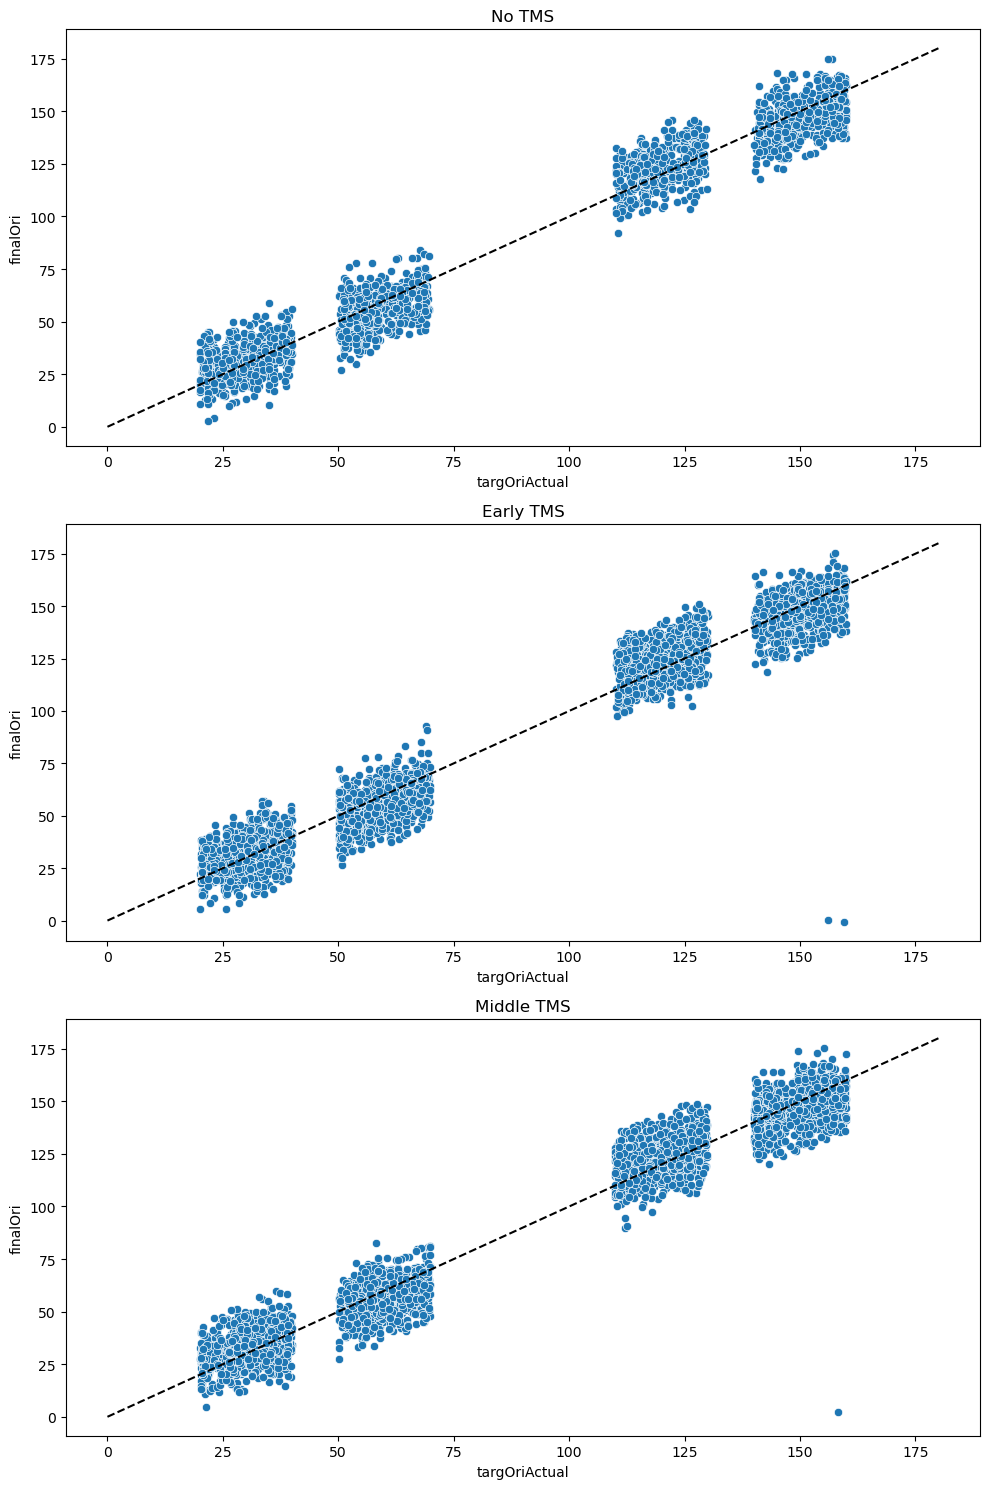

In [53]:
# Create 3 subplots plotting target and final orientation by TMS condition
df_temp = df.copy()
df_temp = df_temp[df_temp['abserrorOri'] < 3 * df_temp['abserrorOri'].std()]
f, axs = plt.subplots(3, 1, figsize=(10, 15))
sns.scatterplot(x='targOriActual', y='finalOri', data=df_temp[df_temp['TMScond_label'] == 'No TMS'], ax=axs[0])
axs[0].plot([0, 180], [0, 180], 'k--')
axs[0].set_title('No TMS')

sns.scatterplot(x='targOriActual', y='finalOri', data=df_temp[df_temp['TMScond_label'] == 'Early TMS'], ax=axs[1])
axs[1].plot([0, 180], [0, 180], 'k--')
axs[1].set_title('Early TMS')

sns.scatterplot(x='targOriActual', y='finalOri', data=df_temp[df_temp['TMScond_label'] == 'Middle TMS'], ax=axs[2])
axs[2].plot([0, 180], [0, 180], 'k--')
axs[2].set_title('Middle TMS')

f.tight_layout()
plt.show()

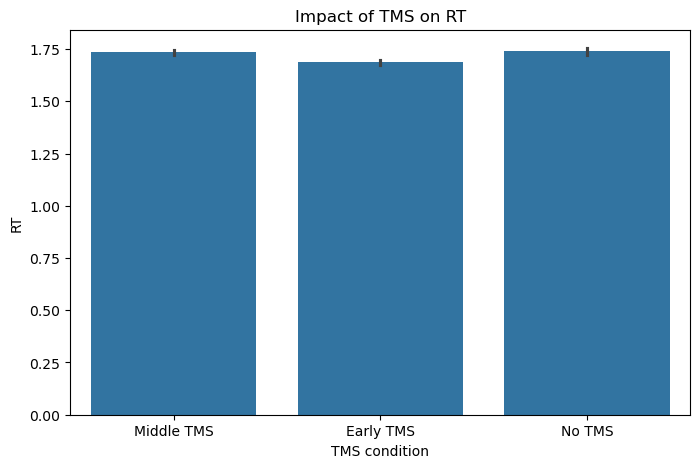

                   Anova
              F Value Num DF  Den DF Pr > F
-------------------------------------------
TMScond_label  1.4466 2.0000 26.0000 0.2537



In [36]:
# Check if TMS impacts RT
plt.figure(figsize=(8, 5))
sns.barplot(x='TMScond_label', y='RT', data=df[df['stimPF'] == 1], errorbar='se')
plt.xlabel('TMS condition')
plt.ylabel('RT')
plt.title('Impact of TMS on RT')
plt.show()

# Perform repeated measures ANOVA on RT
gp_df = df[df['stimPF'] == 1].groupby(['subjID', 'TMScond_label'], observed=False).agg(
    mean_RT=('RT', 'mean'),
    sem_RT=('RT', 'sem')).reset_index()
aovrm = AnovaRM(gp_df, 'mean_RT', 'subjID', within=['TMScond_label'])
res = aovrm.fit()
print(res)

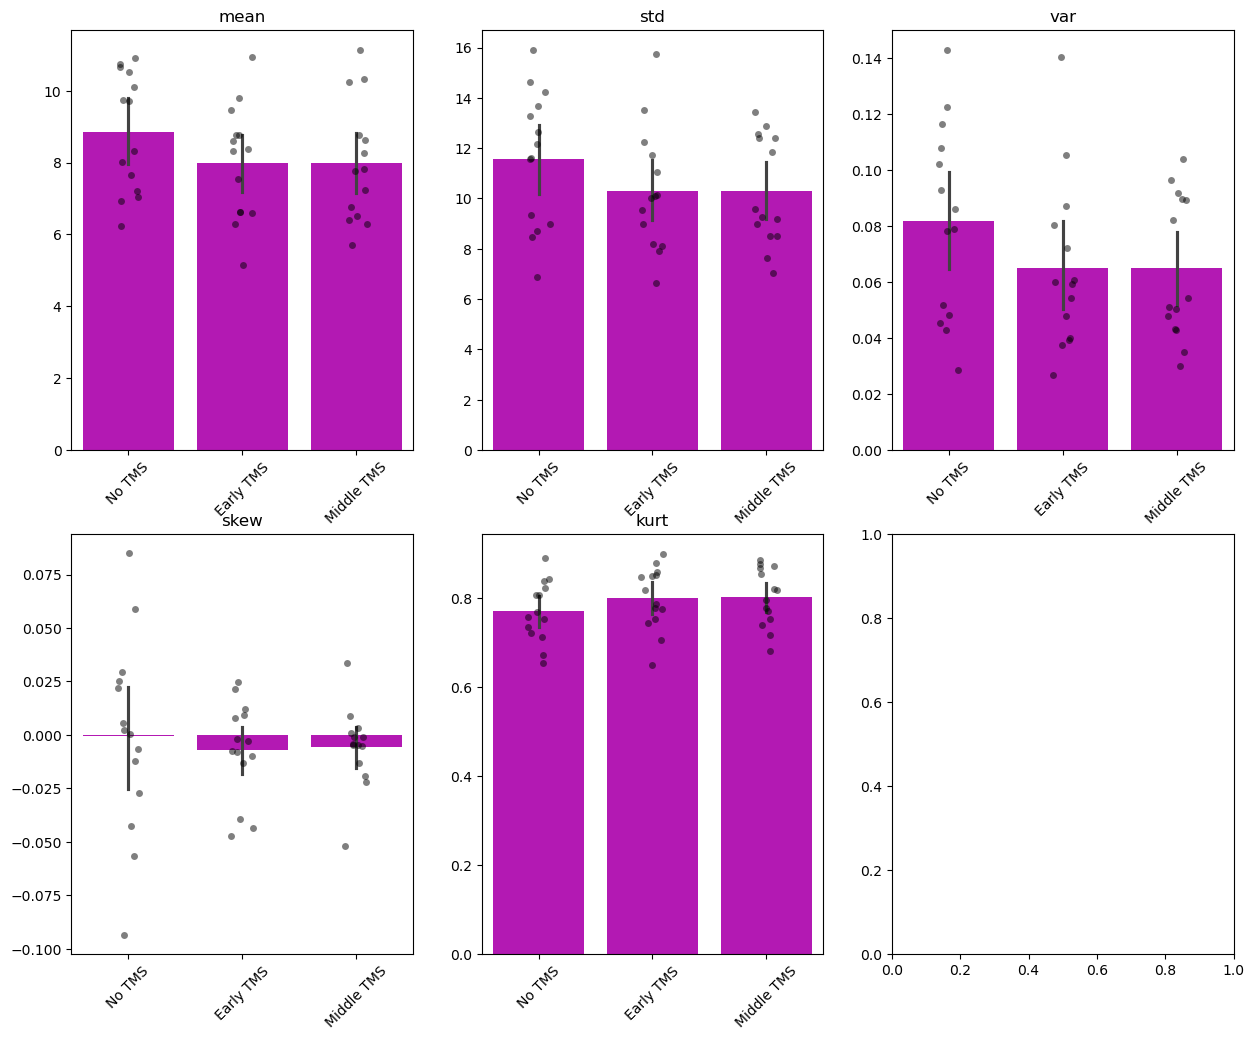

ANOVA results for mean:
                   Anova
              F Value Num DF  Den DF Pr > F
-------------------------------------------
TMS_condition  3.1711 2.0000 26.0000 0.0586



ANOVA results for std:
                   Anova
              F Value Num DF  Den DF Pr > F
-------------------------------------------
TMS_condition  3.1984 2.0000 26.0000 0.0573



ANOVA results for var:
                   Anova
              F Value Num DF  Den DF Pr > F
-------------------------------------------
TMS_condition  3.2070 2.0000 26.0000 0.0569



ANOVA results for skew:
                   Anova
              F Value Num DF  Den DF Pr > F
-------------------------------------------
TMS_condition  0.2184 2.0000 26.0000 0.8052



ANOVA results for kurt:
                   Anova
              F Value Num DF  Den DF Pr > F
-------------------------------------------
TMS_condition  4.6268 2.0000 26.0000 0.0191





In [45]:
# Model-free: Population
summaryData = np.empty((len(df['subjID'].unique()), 5, 3))
orderStats = ['mean', 'std', 'var', 'skew', 'kurt']
metric_to_plot = 'errOri_scaled'
for i, sidx in enumerate(df['subjID'].unique()):
    sTemp = df[(df['subjID'] == sidx) & (df['stimPF'] == 1)]
    # sTemp = sTemp[sTemp['abserrorOri'] < 5 * sTemp['abserrorOri'].std()]
    sTemo = sTemp[(sTemp['initOffset'] > 25) | (sTemp['initOffset'] < -25)]
    
    nt_df = sTemp[sTemp['TMScond_label'] == 'No TMS']
    et_df = sTemp[sTemp['TMScond_label'] == 'Early TMS']
    mt_df = sTemp[sTemp['TMScond_label'] == 'Middle TMS']

    nt_mean, nt_std, nt_var, nt_skew, nt_kurt = circ_stats(nt_df[metric_to_plot])
    et_mean, et_std, et_var, et_skew, et_kurt = circ_stats(et_df[metric_to_plot])
    mt_mean, mt_std, mt_var, mt_skew, mt_kurt = circ_stats(mt_df[metric_to_plot])

    nt_mean = nt_df['abserrorOri'].mean()
    et_mean = et_df['abserrorOri'].mean()
    mt_mean = mt_df['abserrorOri'].mean()

    summaryData[i, :, :] = np.array([[nt_mean, nt_std, nt_var, nt_skew, nt_kurt], [et_mean, et_std, et_var, et_skew, et_kurt], [mt_mean, mt_std, mt_var, mt_skew, mt_kurt]]).T

f, axs = plt.subplots(2, 3, figsize=(15, 12))
axs = axs.flatten()
for i in range(5):
    sns.stripplot(data=summaryData[:, i, :], ax=axs[i], color='black', alpha=0.5, jitter=0.1)
    sns.barplot(data=summaryData[:, i, :], ax=axs[i], color=[0.8, 0, 0.8, 0.8], linewidth=1)
    axs[i].set_xticks([0, 1, 2])
    axs[i].set_xticklabels(['No TMS', 'Early TMS', 'Middle TMS'], rotation=45)
    axs[i].set_title(f'{orderStats[i]}')
plt.show()

# Perform repeated measures ANOVA for each metric
metrics = ['mean', 'std', 'var', 'skew', 'kurt']
results = {}

for i, metric in enumerate(metrics):
    # Reshape data: Each row corresponds to a subject's score in each condition
    data = pd.DataFrame({
        'subject': np.repeat(np.arange(len(df['subjID'].unique())), 3),
        'TMS_condition': np.tile(['No TMS', 'Early TMS', 'Middle TMS'], len(df['subjID'].unique())),
        'metric_value': summaryData[:, i, :].flatten()
    })

    # Perform repeated measures ANOVA
    anova_result = AnovaRM(data, 'metric_value', 'subject', within=['TMS_condition']).fit()
    results[metric] = anova_result

# Print ANOVA results
for metric, result in results.items():
    print(f"ANOVA results for {metric}:")
    print(result)
    print("\n")

# Conclusion:
# TMS has impact on precision of reported orientation but not on accuracy.
# Specifically, TMS reduces precision of memory and the impact is larger for early TMS compared to middle TMS

In [18]:
nsubs = len(df['subjID'].unique())
orderStats = ['mean', 'std', 'var', 'skew', 'kurt']
nstats = len(orderStats)
ntms = df['TMScond_label'].nunique()
nori = df['targOriCategory'].nunique()
nloc = df['stimPF'].nunique()

summaryData = np.empty((nsubs, nstats, ntms, nori, nloc))
metric_to_plot = 'errOri_scaled'

for i, sidx in enumerate(df['subjID'].unique()):
    for j, ori in enumerate(df['targOriCategory'].unique()):
        for k, pf in enumerate(df['stimPF'].unique()):
            sTemp = df[(df['subjID'] == sidx) & (df['stimPF'] == pf) & (df['targOriCategory'] == ori)]
            sTemp = sTemp[sTemp['abserrorOri'] < 3 * sTemp['abserrorOri'].std()]
            # sTemo = sTemp[(sTemp['initOffset'] > 25) | (sTemp['initOffset'] < -25)]
            
            nt_df = sTemp[sTemp['TMScond_label'] == 'No TMS']
            et_df = sTemp[sTemp['TMScond_label'] == 'Early TMS']
            mt_df = sTemp[sTemp['TMScond_label'] == 'Middle TMS']

            nt_mean, nt_std, nt_var, nt_skew, nt_kurt = circ_stats(nt_df[metric_to_plot])
            et_mean, et_std, et_var, et_skew, et_kurt = circ_stats(et_df[metric_to_plot])
            mt_mean, mt_std, mt_var, mt_skew, mt_kurt = circ_stats(mt_df[metric_to_plot])

            nt_mean = nt_df['abserrorOri'].mean()
            et_mean = et_df['abserrorOri'].mean()
            mt_mean = mt_df['abserrorOri'].mean()

            summaryData[i, :, 0, j, k] = np.array([nt_mean, nt_std, nt_var, nt_skew, nt_kurt])
            summaryData[i, :, 1, j, k] = np.array([et_mean, et_std, et_var, et_skew, et_kurt])
            summaryData[i, :, 2, j, k] = np.array([mt_mean, mt_std, mt_var, mt_skew, mt_kurt])

data_for_anova = []

for subj_idx, subj_id in enumerate(df['subjID'].unique()):
    for stat_idx, stat in enumerate(orderStats):
        for tms_idx, tms_cond in enumerate(['No TMS', 'Early TMS', 'Middle TMS']):
            for ori_idx, ori_cat in enumerate(df['targOriCategory'].unique()):
                for stim_idx, stim_pf in enumerate(df['stimPF'].unique()):
                    data_for_anova.append({
                        'subjID': subj_id,
                        'TMScond_label': tms_cond,
                        'stimPF': stim_pf,
                        'targOriCategory': ori_cat,
                        'Statistic': stat,
                        'Value': summaryData[subj_idx, stat_idx, tms_idx, ori_idx, stim_idx]
                    })

from statsmodels.formula.api import ols
import statsmodels.api as sm
anova_df = pd.DataFrame(data_for_anova)
# anova_df.head(20)
# anova_df['TMScond_label'] = anova_df['TMScond_label'].astype('category')
# anova_df['targOriCategory'] = anova_df['targOriCategory'].astype('category')
# anova_df['stimPF'] = anova_df['stimPF'].astype('category')
# anova_df['subjID'] = anova_df['subjID'].astype('category')

# Run ANOVA for each statistic
results = {}
for stat in orderStats:
    anova_stat_df = anova_df[anova_df['Statistic'] == stat]
    model = ols('Value ~ C(targOriCategory) * C(TMScond_label) * C(stimPF) + C(subjID)', data=anova_stat_df).fit()
    aov_table = sm.stats.anova_lm(model, typ=2)
    results[stat] = aov_table
    print(f"ANOVA results for {stat}:")
    print(aov_table)
    print("\n" + "="*40 + "\n")

ANOVA results for mean:
                                                  sum_sq     df       F  \
C(targOriCategory)                               59.6697    3.0  5.6244   
C(TMScond_label)                                  1.9473    2.0  0.2753   
C(stimPF)                                         0.1285    1.0  0.0363   
C(subjID)                                       369.5844   13.0  8.0393   
C(targOriCategory):C(TMScond_label)              20.0125    6.0  0.9432   
C(targOriCategory):C(stimPF)                     25.0092    3.0  2.3574   
C(TMScond_label):C(stimPF)                        6.2046    2.0  0.8773   
C(targOriCategory):C(TMScond_label):C(stimPF)     9.4552    6.0  0.4456   
Residual                                       1057.3642  299.0     NaN   

                                                   PR(>F)  
C(targOriCategory)                             9.2043e-04  
C(TMScond_label)                               7.5952e-01  
C(stimPF)                                    

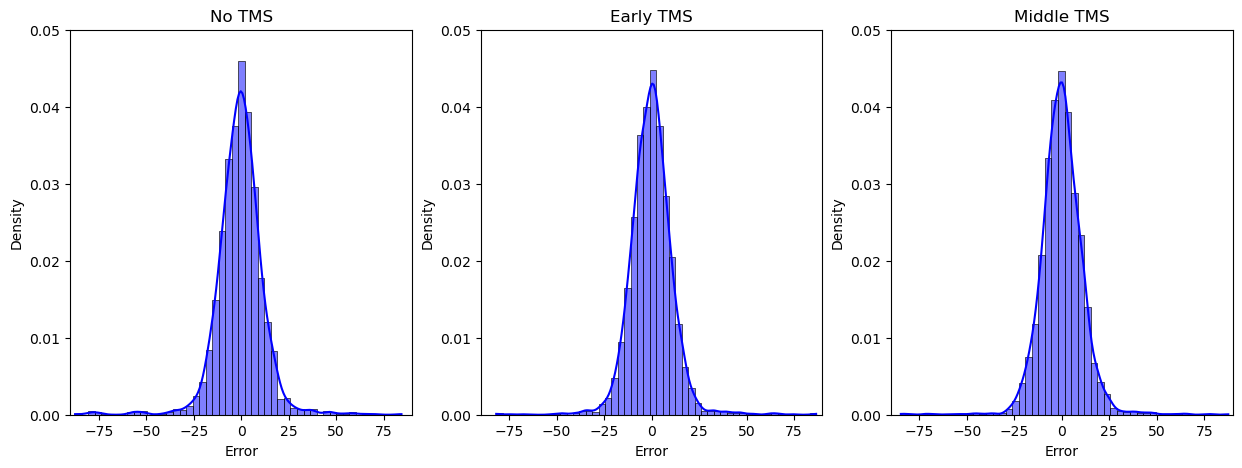

In [120]:
# Visualize circular histogram of errors for each TMS condition
df_temp = df.copy()
# df_temp = df_temp[df_temp['abserrorOri'] < 3 * df_temp['abserrorOri'].std()]
f, axs = plt.subplots(1, 3, figsize=(15, 5))
for i, tms_cond in enumerate(['No TMS', 'Early TMS', 'Middle TMS']):
    thErr = df_temp[df_temp['TMScond_label'] == tms_cond]['errOri_scaled']
    
    sns.histplot(df_temp[df_temp['TMScond_label'] == tms_cond]['errOri_scaled'], bins=50, ax=axs[i], kde=True, color='blue',
                    stat='density')
    
    axs[i].set_title(tms_cond)
    axs[i].set_xlabel('Error')
    axs[i].set_ylabel('Density')
    axs[i].set_xlim([-90, 90])
    axs[i].set_ylim([0, 0.05])
plt.show()

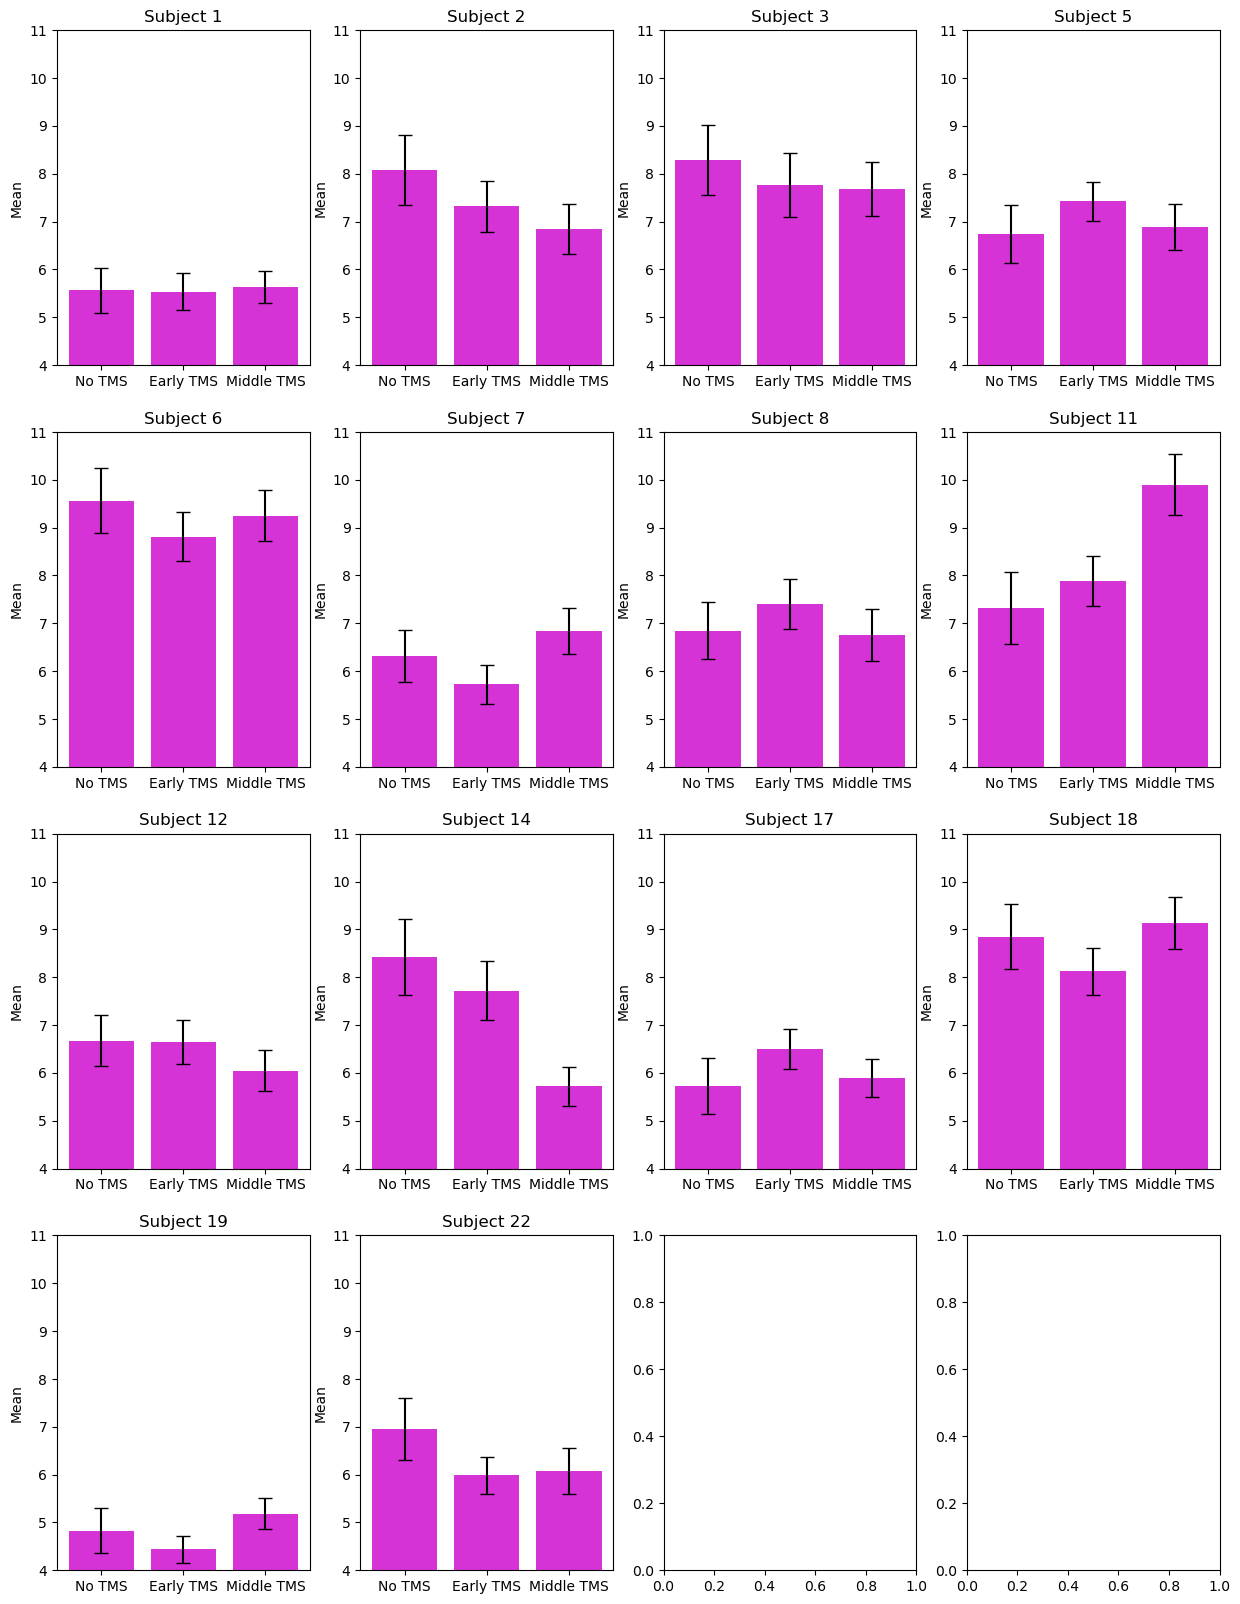

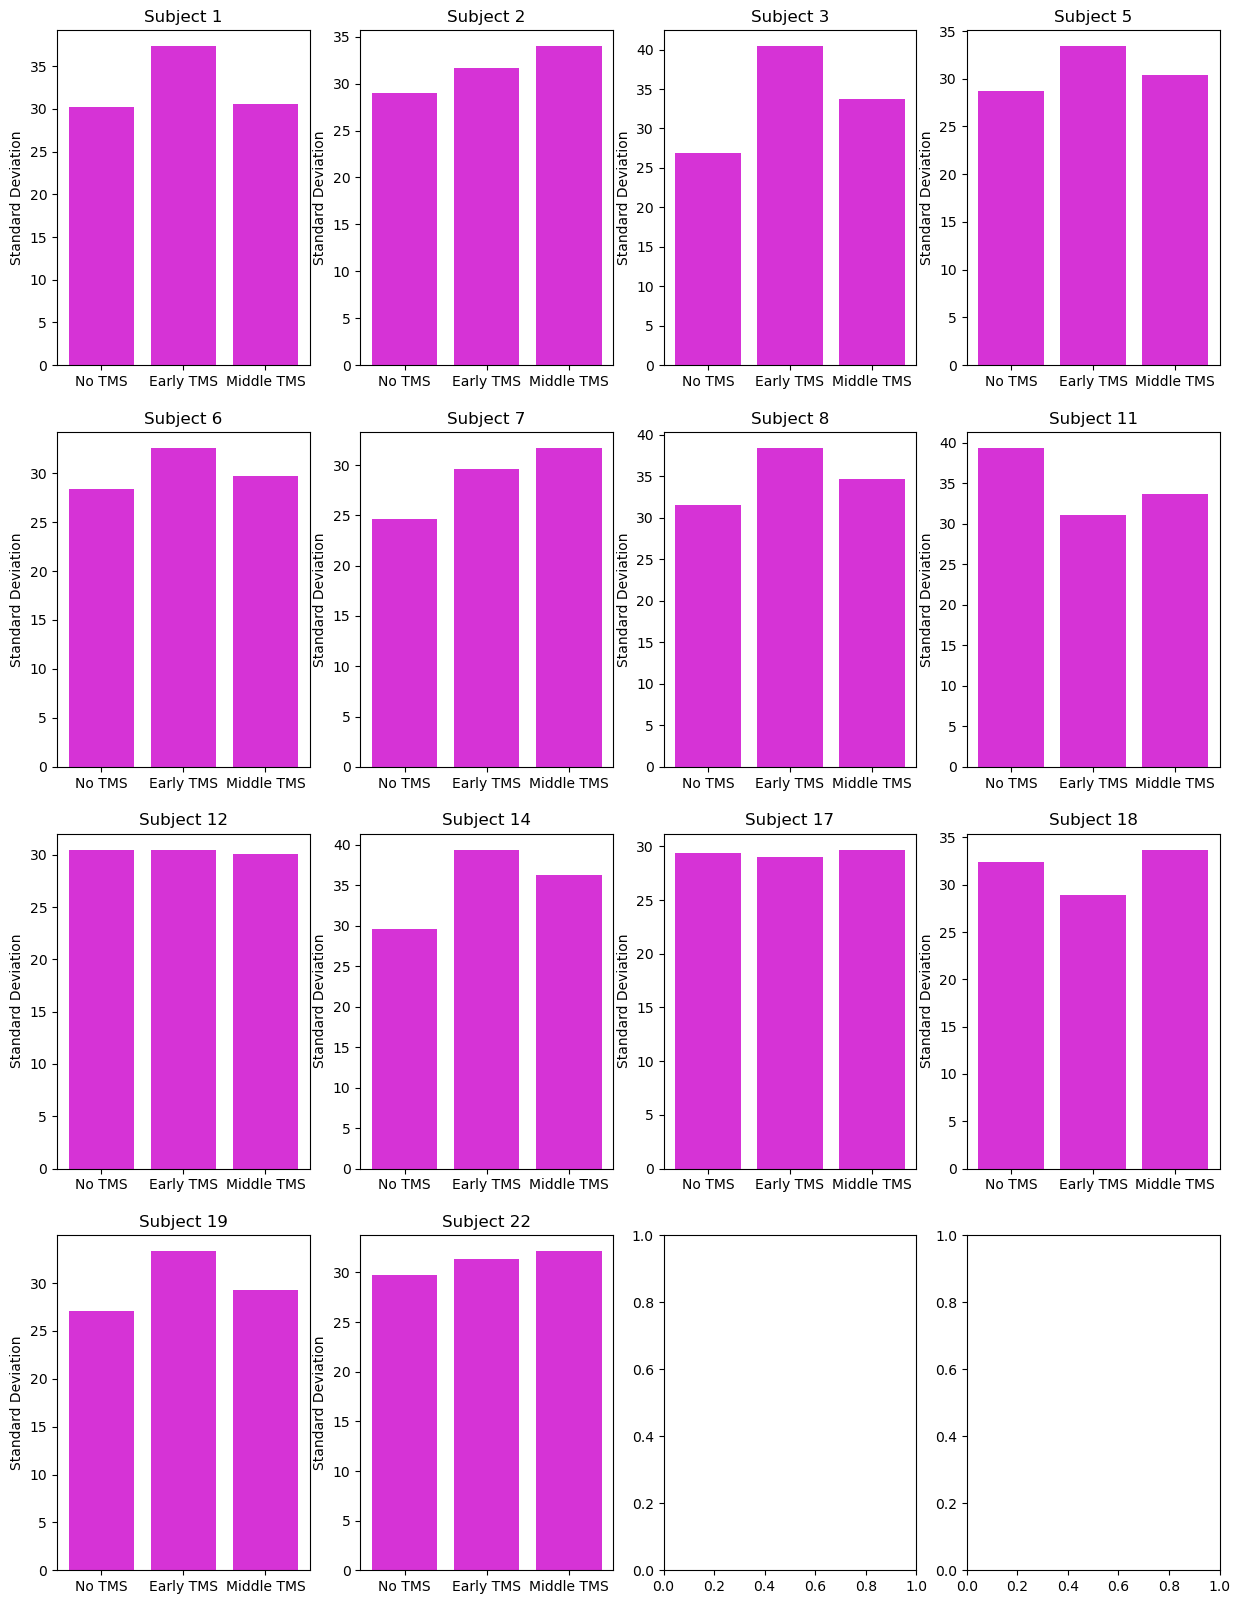

In [8]:
# Model-based: Individual
orderStats = ['mean', 'std', 'var', 'skew', 'kurt']
metric_to_plot = 'errOri_scaled'
ncols = 4
nrows = df['subjID'].nunique() // ncols + 1
f1, axs1 = plt.subplots(nrows, ncols, figsize=(15, 20))
axs1 = axs1.flatten()
f2, axs2 = plt.subplots(nrows, ncols, figsize=(15, 20))
axs2 = axs2.flatten()
for i, sidx in enumerate(df['subjID'].unique()):
    sTemp = df[(df['subjID'] == sidx) & (df['stimPF'] == 1)]
    sTemp = sTemp[sTemp['abserrorOri'] < 3 * sTemp['abserrorOri'].std()]
    # sTemo = sTemp[(sTemp['initOffset'] > 25) | (sTemp['initOffset'] < -25)]
    
    nt_df = sTemp[sTemp['TMScond_label'] == 'No TMS']
    et_df = sTemp[sTemp['TMScond_label'] == 'Early TMS']
    mt_df = sTemp[sTemp['TMScond_label'] == 'Middle TMS']

    nt_mean, nt_std, nt_var, nt_skew, nt_kurt = circ_stats(nt_df[metric_to_plot])
    et_mean, et_std, et_var, et_skew, et_kurt = circ_stats(et_df[metric_to_plot])
    mt_mean, mt_std, mt_var, mt_skew, mt_kurt = circ_stats(mt_df[metric_to_plot])

    nt_mean = nt_df['abserrorOri'].mean()
    et_mean = et_df['abserrorOri'].mean()
    mt_mean = mt_df['abserrorOri'].mean()
    nt_serr = nt_df['abserrorOri'].sem()
    et_serr = et_df['abserrorOri'].sem()
    mt_serr = mt_df['abserrorOri'].sem()

    axs1[i].bar(['No TMS', 'Early TMS', 'Middle TMS'], [nt_mean, et_mean, mt_mean], color=[0.8, 0, 0.8, 0.8], yerr=[nt_serr, et_serr, mt_serr], capsize=5)
    axs1[i].set_title(f'Subject {sidx}')
    axs1[i].set_ylabel('Mean')
    axs1[i].set_ylim([4, 11])

    axs2[i].bar(['No TMS', 'Early TMS', 'Middle TMS'], [nt_std, et_std, mt_std], color=[0.8, 0, 0.8, 0.8])
    axs2[i].set_title(f'Subject {sidx}')
    axs2[i].set_ylabel('Standard Deviation')
plt.show()

Optimization successful after 20 iterations, NLL = 18.814976618374885
Optimization successful after 21 iterations, NLL = 17.776753742072405
Optimization successful after 21 iterations, NLL = 13.770223318679434
Optimization successful after 20 iterations, NLL = 18.814976618378097
Optimization successful after 20 iterations, NLL = 17.776753742081862
Optimization successful after 20 iterations, NLL = 13.77022331870405
Optimization successful after 22 iterations, NLL = 18.797062004225026
Optimization successful after 20 iterations, NLL = 16.152050803814763
Optimization successful after 20 iterations, NLL = 11.518312353428012
Optimization successful after 23 iterations, NLL = 48.14836537488097
Optimization successful after 21 iterations, NLL = 61.723921098658
Optimization successful after 21 iterations, NLL = 38.5784379307344
Optimization successful after 20 iterations, NLL = 43.029156146119064
Optimization successful after 20 iterations, NLL = 61.72392109865851
Optimization successful afte

/System/Volumes/Data/d/DATD/hyper/experiments/Mrugank/TMS/srh_ori/oriAnalysis/analyzeBehav/modeller.py:129: RuntimeWarning: divide by zero encountered in log
  nll = -np.sum(np.log(pdf) + 1e-10) # Add a small number to avoid log(0)
/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/scipy/optimize/_numdiff.py:576: RuntimeWarning: invalid value encountered in subtract
  df = fun(x) - f0


Optimization successful after 21 iterations, NLL = 8.819207533424965
Optimization successful after 22 iterations, NLL = 54.399657737656554
Optimization successful after 34 iterations, NLL = 99.21338695139144
Optimization successful after 20 iterations, NLL = 70.45005389561993
Optimization successful after 20 iterations, NLL = 52.428101543822834
Optimization successful after 20 iterations, NLL = 85.34418471321399
Optimization successful after 20 iterations, NLL = 49.70283116851187
Optimization successful after 21 iterations, NLL = 52.22716811209412
Optimization successful after 22 iterations, NLL = 85.2710842540533
Optimization successful after 22 iterations, NLL = 48.25463147622354
Optimization successful after 21 iterations, NLL = 40.591984575462035
Optimization successful after 21 iterations, NLL = 19.436432957105037
Optimization successful after 21 iterations, NLL = 25.433998957208047
Optimization successful after 20 iterations, NLL = 30.038302038176425
Optimization successful after

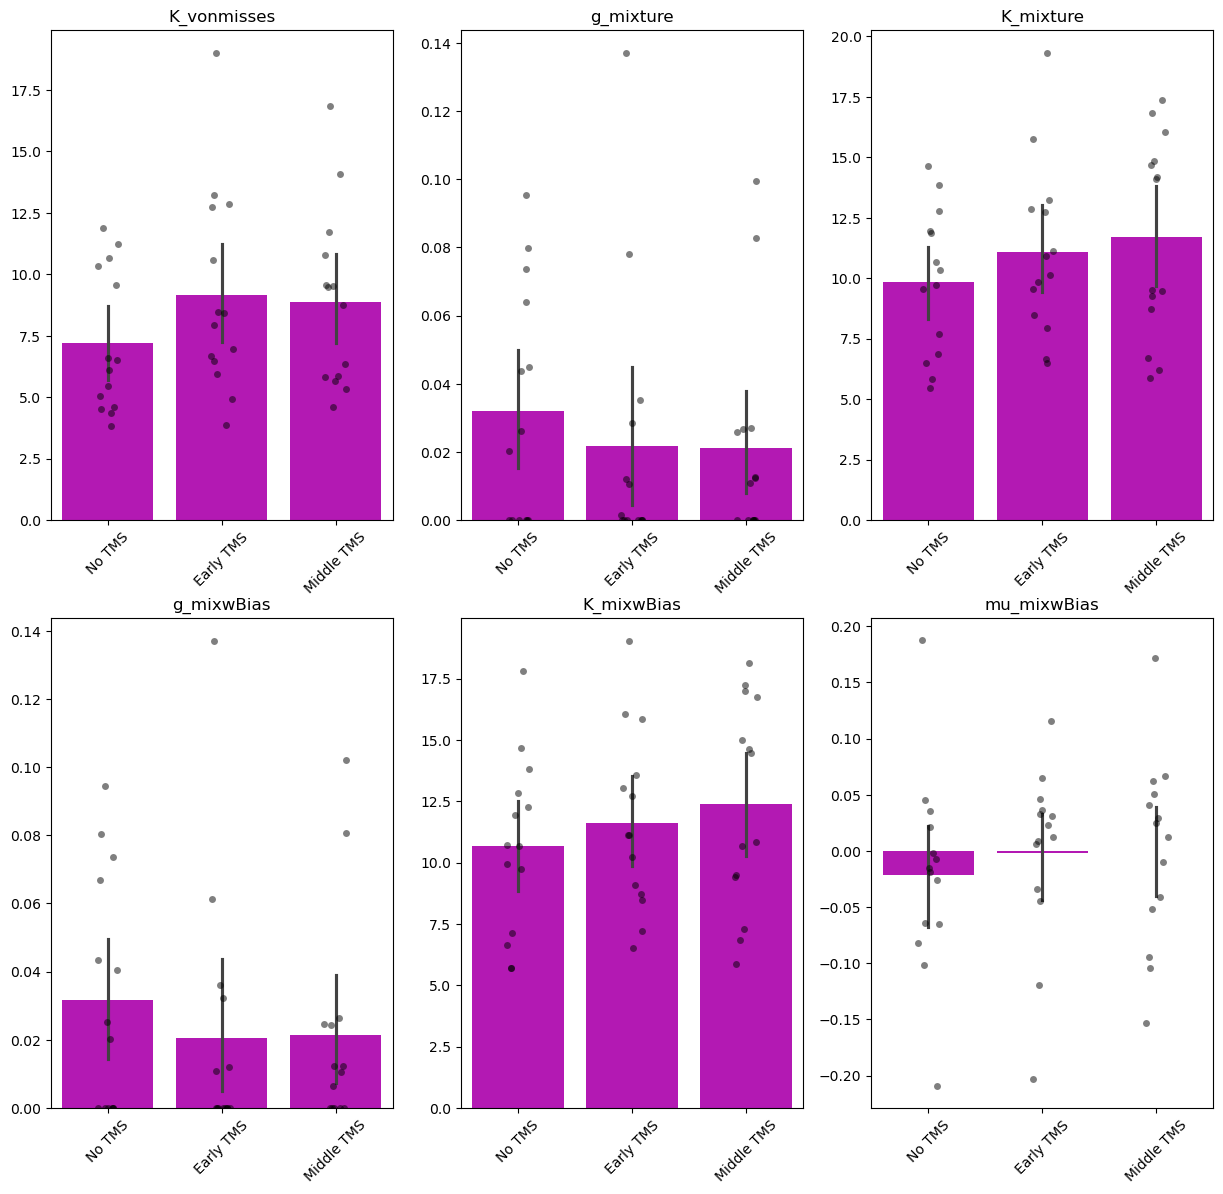

In [106]:
# Model-based: Population (Mixture model)
orderStats = ['K_vonmisses', 'g_mixture', 'K_mixture', 'g_mixwBias', 'K_mixwBias', 'mu_mixwBias']
summaryData = np.empty((len(df['subjID'].unique()), len(orderStats), 3))

metric_to_plot = 'errOri_scaled'
# df_temp['errOri_nobias'] = np.nan
# Fit a 4th order polynomial to the error data and remove the bias for each subject
for i, sidx in enumerate(df_temp['subjID'].unique()):
    subdf = df_temp[df_temp['subjID'] == sidx]
    
for i, sidx in enumerate(df['subjID'].unique()):
    sTemp = df[(df['subjID'] == sidx) & (df['stimPF'] == 1)]

    # Fit a 4th order polynomial to the error data
    # errorVals = sTemp['errOri_scaled'].values
    # x = sTemp['targOriActual'].values
    # y = errorVals
    # model = np.poly1d(np.polyfit(x, y, 4))
    # yfit = model(x)
    # sTemp.loc[sTemp['subjID'] == sidx, 'errOri_scaled'] = errorVals - yfit

    # sTemp = sTemp[sTemp['abserrorOri'] < 3 * sTemp['abserrorOri'].std()]
    # sTemp = sTemp[(sTemp['initOffset'] > 25) | (sTemp['initOffset'] < -25)]
    
    nt_df = sTemp[sTemp['TMScond_label'] == 'No TMS']
    et_df = sTemp[sTemp['TMScond_label'] == 'Early TMS']
    mt_df = sTemp[sTemp['TMScond_label'] == 'Middle TMS']

    # Fit von Mises model
    nt_vm_fit = fit_model(nt_df[metric_to_plot], 'vonMises')
    et_vm_fit = fit_model(et_df[metric_to_plot], 'vonMises')
    mt_vm_fit = fit_model(mt_df[metric_to_plot], 'vonMises')
    nt_k_vonmises, et_k_vonmises, mt_k_vonmises = nt_vm_fit[0], et_vm_fit[0], mt_vm_fit[0]

    # Fit mixture model
    nt_mix_fit = fit_model(nt_df[metric_to_plot], 'mixtureModel')
    et_mix_fit = fit_model(et_df[metric_to_plot], 'mixtureModel')
    mt_mix_fit = fit_model(mt_df[metric_to_plot], 'mixtureModel')
    nt_g_mixture, nt_K_mixture = nt_mix_fit[0], nt_mix_fit[1]
    et_g_mixture, et_K_mixture = et_mix_fit[0], et_mix_fit[1]
    mt_g_mixture, mt_K_mixture = mt_mix_fit[0], mt_mix_fit[1]

    # Fit mixture model with bias
    nt_mixwBias_fit = fit_model(nt_df[metric_to_plot], 'mixtureModelwithBias')
    et_mixwBias_fit = fit_model(et_df[metric_to_plot], 'mixtureModelwithBias')
    mt_mixwBias_fit = fit_model(mt_df[metric_to_plot], 'mixtureModelwithBias')
    nt_g_mixwBias, nt_K_mixwBias, nt_mu_mixwBias = nt_mixwBias_fit[0], nt_mixwBias_fit[1], nt_mixwBias_fit[2]
    et_g_mixwBias, et_K_mixwBias, et_mu_mixwBias = et_mixwBias_fit[0], et_mixwBias_fit[1], et_mixwBias_fit[2]
    mt_g_mixwBias, mt_K_mixwBias, mt_mu_mixwBias = mt_mixwBias_fit[0], mt_mixwBias_fit[1], mt_mixwBias_fit[2]

    # summaryData[i, :, :] = np.array([[nt_g, nt_K], [et_g, et_K], [mt_g, mt_K]]).T
    summaryData[i, :, :] = np.array([[nt_k_vonmises, nt_g_mixture, nt_K_mixture, nt_g_mixwBias, nt_K_mixwBias, nt_mu_mixwBias], 
                                     [et_k_vonmises, et_g_mixture, et_K_mixture, et_g_mixwBias, et_K_mixwBias, et_mu_mixwBias], 
                                     [mt_k_vonmises, mt_g_mixture, mt_K_mixture, mt_g_mixwBias, mt_K_mixwBias, mt_mu_mixwBias]]).T

ncols = 3
nrows = len(orderStats) // ncols 
f, axs = plt.subplots(nrows, ncols, figsize=(15, nrows*7))
axs = axs.flatten()
for i in range(len(orderStats)):
    sns.stripplot(data=summaryData[:, i, :], ax=axs[i], color='black', alpha=0.5, jitter=0.1)
    sns.barplot(data=summaryData[:, i, :], ax=axs[i], color=[0.8, 0, 0.8, 0.8], linewidth=1)# showfliers=False)
    axs[i].set_xticks([0, 1, 2])
    axs[i].set_xticklabels(['No TMS', 'Early TMS', 'Middle TMS'], rotation=45)
    axs[i].set_title(f'{orderStats[i]}')

# Perform repeated measures ANOVA for each metric
metrics = ['K_vonmisses', 'g_mixture', 'K_mixture', 'g_mixwBias', 'K_mixwBias', 'mu_mixwBias']
results = {}

for i, metric in enumerate(metrics):
    # Reshape data: Each row corresponds to a subject's score in each condition
    data = pd.DataFrame({
        'subject': np.repeat(np.arange(len(df['subjID'].unique())), 3),
        'TMS_condition': np.tile(['No TMS', 'Early TMS', 'Middle TMS'], len(df['subjID'].unique())),
        'metric_value': summaryData[:, i, :].flatten()
    })

    # Perform repeated measures ANOVA
    anova_result = AnovaRM(data, 'metric_value', 'subject', within=['TMS_condition']).fit()
    results[metric] = anova_result

# Print ANOVA results
for metric, result in results.items():
    print(f"ANOVA results for {metric}:")
    print(result)
    print("\n")

<Figure size 1000x500 with 0 Axes>

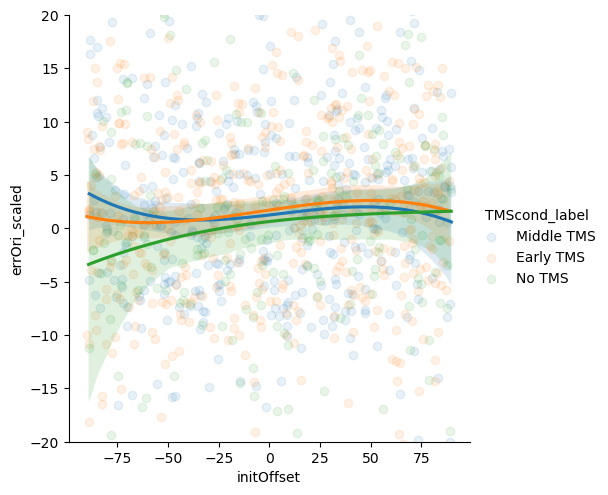

In [29]:
plt.figure(figsize=(10, 5))
df_temp = df[df['stimPF'] == 1].copy()
sns.lmplot(x='initOffset', y='errOri_scaled', data=df_temp[df_temp['targOriCategory'] == 30], order=3, hue='TMScond_label', scatter_kws={'alpha': 0.1})
plt.ylim(-20, 20)
plt.show()

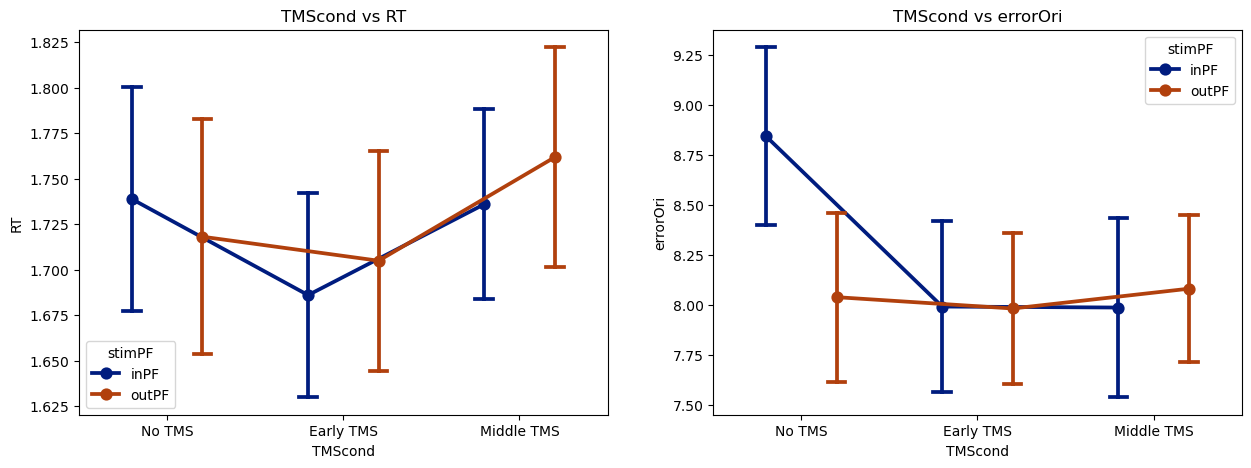

In [64]:
grouped_df = df.groupby(['subjID', 'TMScond_label', 'stimPF_label']).agg({
    'RT': ['mean', 'sem'],
    'abserrorOri': ['mean', 'sem']
}).reset_index()

grouped_df.columns = ['subjID', 'TMScond', 'stimPF', 'RT_mean', 'RT_sem', 'abserrorOri_mean', 'abserrorOri_sem']

f, axs = plt.subplots(1, 2, figsize=(15, 5))

sns.pointplot(x='TMScond', y='RT_mean', data=grouped_df, ax=axs[0], hue='stimPF', dodge=0.4, 
              markers='o', capsize=.1, palette='dark', errorbar='se', order=['No TMS', 'Early TMS', 'Middle TMS'])

axs[0].set_title('TMScond vs RT')
axs[0].set_xlabel('TMScond')
axs[0].set_ylabel('RT')

sns.pointplot(x='TMScond', y='abserrorOri_mean', data=grouped_df, ax=axs[1], hue='stimPF', dodge=0.4, 
              markers='o', capsize=.1, palette='dark', errorbar='se', order=['No TMS', 'Early TMS', 'Middle TMS'])

axs[1].set_title('TMScond vs errorOri')
axs[1].set_xlabel('TMScond')
axs[1].set_ylabel('errorOri')

plt.show()

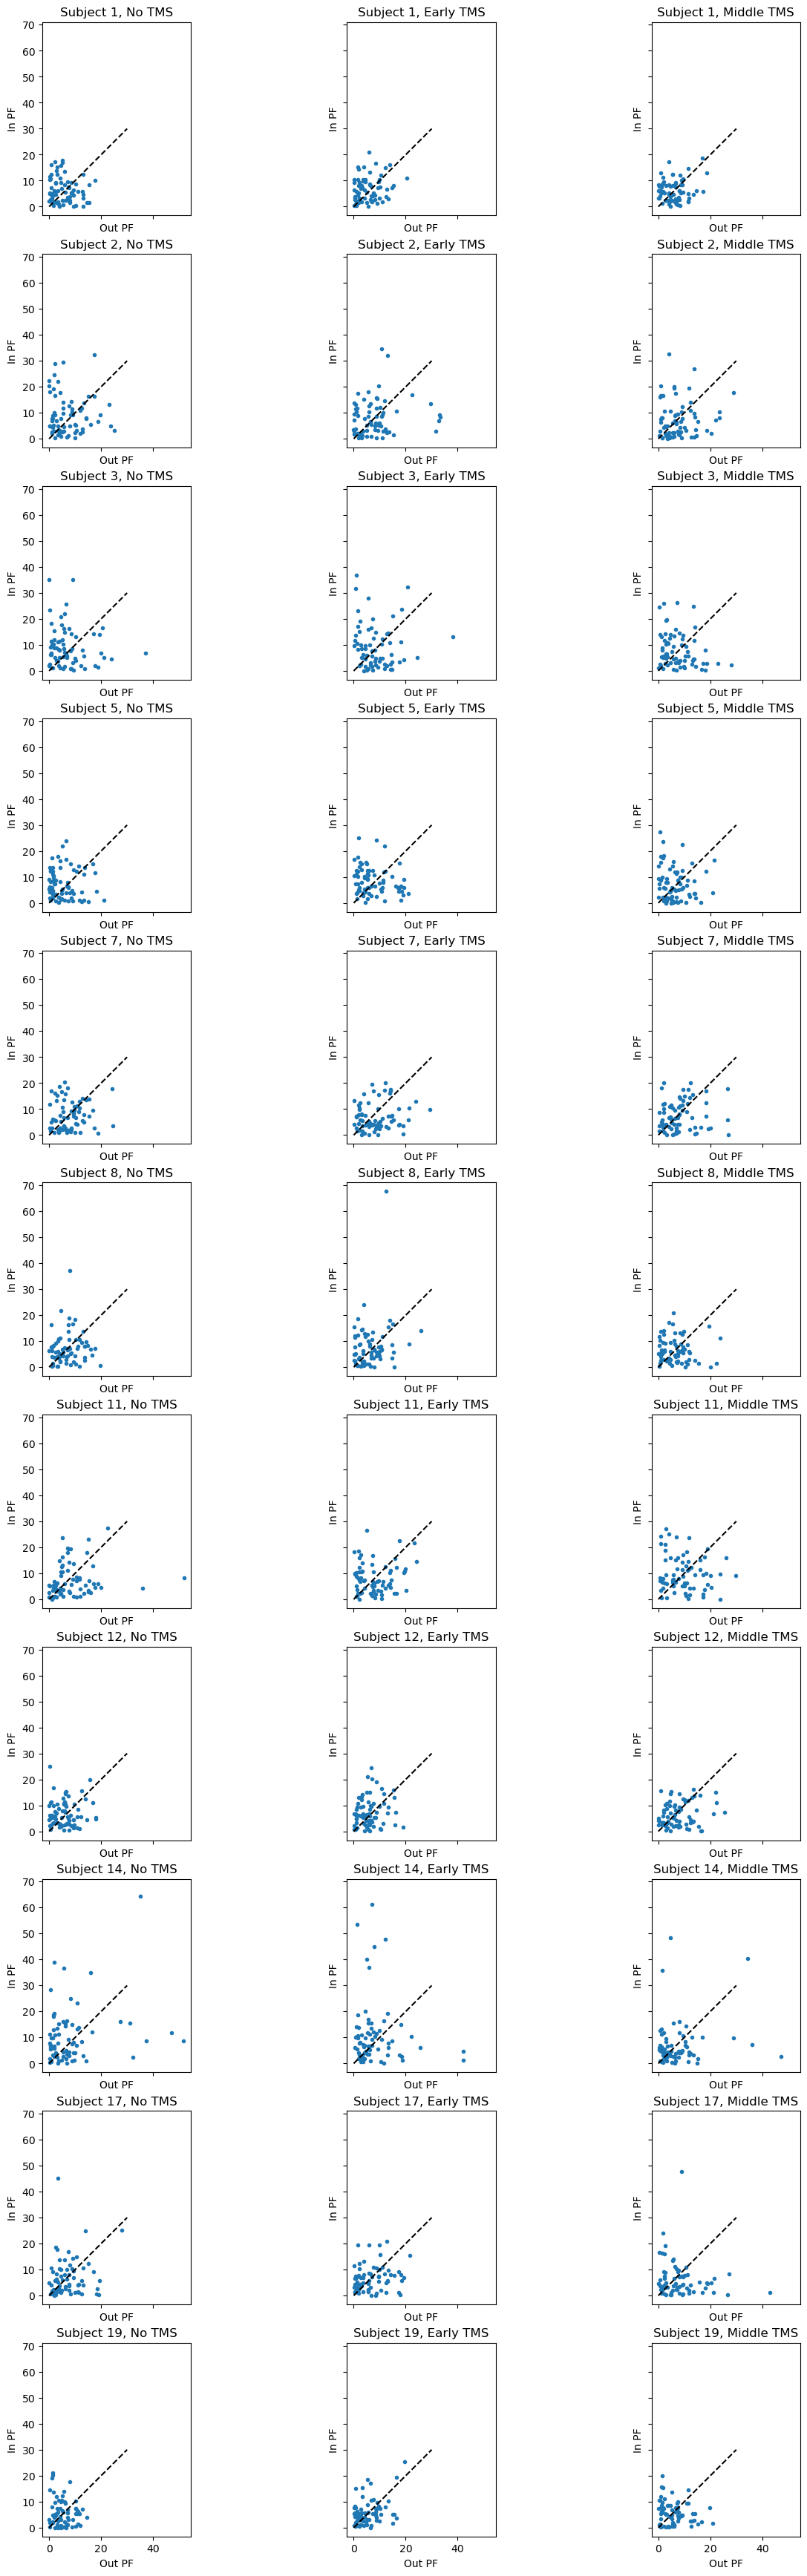

In [10]:
f, axs = plt.subplots(df['subjID'].nunique(), 3, figsize=(15, 4*df['subjID'].nunique()), sharex=True, sharey=True)
meetric_to_plot = 'abserrorOri'
for idx, sub in enumerate(df['subjID'].unique()):
    subdf = df[df['subjID'] == sub]
    elimTrials = np.abs(subdf['abserrorOri'] - subdf['abserrorOri'].mean()) > 3*subdf['abserrorOri'].std()
    subdf = subdf[~elimTrials]
    # Find the number of trials for each TMS condition and stimulus position
    ntrls_noTMS_outPF = subdf[(subdf['TMScond']==1) & (subdf['stimPF']==0)].shape[0]
    ntrls_noTMS_inPF = subdf[(subdf['TMScond']==1) & (subdf['stimPF']==1)].shape[0]
    ntrls_earlyTMS_outPF = subdf[(subdf['TMScond']==2) & (subdf['stimPF']==0)].shape[0]
    ntrls_earlyTMS_inPF = subdf[(subdf['TMScond']==2) & (subdf['stimPF']==1)].shape[0]
    ntrls_middleTMS_outPF = subdf[(subdf['TMScond']==3) & (subdf['stimPF']==0)].shape[0]
    ntrls_middleTMS_inPF = subdf[(subdf['TMScond']==3) & (subdf['stimPF']==1)].shape[0]

    ntrls_min = min(ntrls_noTMS_outPF, ntrls_noTMS_inPF, ntrls_earlyTMS_outPF, ntrls_earlyTMS_inPF, ntrls_middleTMS_outPF, ntrls_middleTMS_inPF)
    subdf = subdf.groupby(['TMScond', 'stimPF']).apply(lambda x: x.sample(n=ntrls_min)).reset_index(drop=True)

    axs[idx, 0].plot(subdf[(subdf['TMScond']==1) & (subdf['stimPF']==0)][metric_to_plot], subdf[(subdf['TMScond']==1) & (subdf['stimPF']==1)][metric_to_plot], 'o', markersize=msize*0.3)
    axs[idx, 0].plot([0, 30], [0, 30], 'k--')
    axs[idx, 0].set_title(f'Subject {sub}, No TMS')
    axs[idx, 0].set_xlabel('Out PF')
    axs[idx, 0].set_ylabel('In PF')
    axs[idx, 0].set_aspect('equal')

    axs[idx, 1].plot(subdf[(subdf['TMScond']==2) & (subdf['stimPF']==0)][metric_to_plot], subdf[(subdf['TMScond']==2) & (subdf['stimPF']==1)][metric_to_plot], 'o', markersize=msize*0.3)
    axs[idx, 1].plot([0, 30], [0, 30], 'k--')
    axs[idx, 1].set_title(f'Subject {sub}, Early TMS')
    axs[idx, 1].set_xlabel('Out PF')
    axs[idx, 1].set_ylabel('In PF')
    axs[idx, 1].set_aspect('equal')

    axs[idx, 2].plot(subdf[(subdf['TMScond']==3) & (subdf['stimPF']==0)][metric_to_plot], subdf[(subdf['TMScond']==3) & (subdf['stimPF']==1)][metric_to_plot], 'o', markersize=msize*0.3)
    axs[idx, 2].plot([0, 30], [0, 30], 'k--')
    axs[idx, 2].set_title(f'Subject {sub}, Middle TMS')
    axs[idx, 2].set_xlabel('Out PF')
    axs[idx, 2].set_ylabel('In PF')
    axs[idx, 2].set_aspect('equal')
plt.show()
    